<h1 style="text-align:center;font-weight:700">基于全量召回记录的消费品危险类型预测</h1>

<p style="text-align:center;font-size:.94em">产品大类全量分析与家用设备子类对照</p>

<p style="text-align:center;font-size:.94em">STAT 4073 数据挖掘课程项目实验 A 与 B</p>

## 摘要

<p style="text-indent:2em;line-height:1.65">本文检验失效构成相近的消费品能否共享危险提示。研究纳入 RECALL-MM 的全部 6,874 条记录，覆盖 11 个产品大类和 6,464 个召回编号。实验 A 使用 Apriori 建立产品类别与危险标签的关联，实验 B 使用 K-means 对早期失效比例分组，再等权结合本类和同簇类别的危险频率。以 2000–2018 年为建模期，在 2019–2024 年的 1,491 个召回编号与大类组合上评价。A 和 B 的命中率分别为 70.4% 和 61.8%，micro-F1 分别为 0.442 和 0.377。在同一批 73 起家用设备召回上，使用大类提示的 A 命中 45 起，使用产品子类提示的 A 命中 57 起。全量结果说明跨类等权借鉴的收益集中在少数类别，家用设备对照说明已知具体子类时可以提供更有针对性的提示。</p>

**关键词** 消费品召回；危险标签；Apriori；K-means；回顾性评价

## 1 引言

<p style="text-indent:2em;line-height:1.65">在产品设计复查阶段，设计人员可以查阅相同或相似产品的历史事故记录。产品的失效方式描述发生了什么，例如部件断裂。危险标签描述可能产生的后果，例如跌落或撞击伤害。具有相似失效方式的大类能否共享危险经验，需要通过后期召回验证。本文先测量本类历史能覆盖多少后期危险，再检验加入同簇经验后，新增和遗漏的危险能否带来整体改善。</p>

<p style="text-indent:2em;line-height:1.65">RECALL-MM 基于美国消费品安全委员会的召回资料构建，原研究使用产品名称和召回描述的文本表示探索相似性[1]。本文先用数据集统一提供的大类标签覆盖全部记录，比较 A 和 B 的总体表现。再以家用设备做子类对照，检验在已知空调及热泵、取暖器或锅炉等具体产品类型时，细分历史能否改善提示。原始产品名称没有覆盖全库的统一子类标签，家用设备的子类由既有名称词典提取。</p>

## 2 数据范围与预处理

<p style="text-align:center;font-size:.94em">表 1  全量数据及时间划分</p>

<table style="border-collapse:collapse;width:100%;margin:auto;font-size:.95em">
<thead>
<tr>
<th style="background-color:#416DA3;color:#FFFFFF;text-align:left;width:34.13%;border:1px solid #D2DEEB;padding:6px 8px">范围</th>
<th style="background-color:#416DA3;color:#FFFFFF;text-align:center;width:17.14%;border:1px solid #D2DEEB;padding:6px 8px">召回编号</th>
<th style="background-color:#416DA3;color:#FFFFFF;text-align:center;width:19.67%;border:1px solid #D2DEEB;padding:6px 8px">编号 × 大类</th>
<th style="background-color:#416DA3;color:#FFFFFF;text-align:center;width:29.06%;border:1px solid #D2DEEB;padding:6px 8px">识别到失效的组合</th>
</tr>
</thead>
<tbody>
<tr>
<td style="background-color:#E8EFF8;color:#111827;text-align:left;width:34.13%;border:1px solid #D2DEEB;padding:6px 8px">全部 2000–2024 年</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:17.14%;border:1px solid #D2DEEB;padding:6px 8px">6,464</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:19.67%;border:1px solid #D2DEEB;padding:6px 8px">6,507</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:29.06%;border:1px solid #D2DEEB;padding:6px 8px">3,373</td>
</tr>
<tr>
<td style="background-color:#F7FAFD;color:#111827;text-align:left;width:34.13%;border:1px solid #D2DEEB;padding:6px 8px">建模期 2000–2018 年</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:17.14%;border:1px solid #D2DEEB;padding:6px 8px">4,978</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:19.67%;border:1px solid #D2DEEB;padding:6px 8px">5,016</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:29.06%;border:1px solid #D2DEEB;padding:6px 8px">2,653</td>
</tr>
<tr>
<td style="background-color:#E8EFF8;color:#111827;text-align:left;width:34.13%;border:1px solid #D2DEEB;padding:6px 8px">评价期 2019–2024 年</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:17.14%;border:1px solid #D2DEEB;padding:6px 8px">1,486</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:19.67%;border:1px solid #D2DEEB;padding:6px 8px">1,491</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:29.06%;border:1px solid #D2DEEB;padding:6px 8px">720</td>
</tr>
</tbody></table>

<p style="text-indent:2em;line-height:1.65">按「召回编号 × 产品大类」合并重复记录。同一组合中的相同危险标签或相同失效方式只计一次。42 个召回编号跨越多个大类，这些召回保留各大类对应的原始危险标签。时间划分按召回编号进行，同一编号不会同时进入建模期和评价期。11 个大类全部满足早期至少 10 起召回、其中至少 5 起识别到失效方式的条件。</p>

<p style="text-indent:2em;line-height:1.65">使用原实验的六类英文关键词从公告描述中识别失效方式。建模期的识别覆盖率为 52.9%，评价期为 48.3%。没有匹配到关键词的召回仍用于危险频率和最终计分。</p>

## 3 实验设计与评价

### 3.1 实验 A 本类历史

<p style="text-indent:2em;line-height:1.65">Apriori 先计数单项，再生成并筛选二项候选[2]。产品大类和危险标签须在同类原始记录中共现，规则以独立召回编号去重。规则支持度等于共现次数除以早期全部召回编号数。置信度等于共现次数除以本类早期召回数。提升度等于置信度除以该危险的总体早期频率。本文逐条用直接计数核验 Apriori 的结果。正文用至少 5 次共现筛选显示规则，预测得分使用全部本类早期危险比例。另计算全期关联规则，用于描述全部数据的历史构成。</p>

### 3.2 实验 B 同簇经验

<p style="text-indent:2em;line-height:1.65">将每个大类表示为六维失效比例。每项比例的分母为该类早期至少识别到一种失效方式的召回数。K-means 使用欧氏距离、K-means++ 初始化、随机种子 42 和 50 次初始化，主实验固定 3 簇[3]。对目标大类先取其他同簇大类各自的危险比例，再按大类等权平均。最终得分由本类频率和这一同簇平均各贡献 50%。</p>

### 3.3 提示阈值的选择

<p style="text-indent:2em;line-height:1.65">A 的得分是本类历史危险比例，B 的得分是本类比例与同簇平均比例的等权组合。得分达到阈值的危险全部纳入，如果少于两项，就按分数取前两项。得分并列时，依次按早期全局频数和标签名称排序。阈值决定要提示多少种危险。关联规则表至少 5 起共现的展示门槛用于筛选正文中的历史规则。</p>

<p style="text-indent:2em;line-height:1.65">用 2000–2013 年的数据估计 A 的危险比例，在 2014–2018 年的 1,263 个编号与大类组合上比较候选阈值。先选 micro-F1 较高的方案，并列时优先选择提示更少的方案，仍并列则取较低的阈值。</p>

<p style="text-align:center;font-size:.94em">表 2  使用早期验证集比较预测阈值</p>

<table style="border-collapse:collapse;width:100%;margin:auto;font-size:.95em">
<thead>
<tr>
<th style="background-color:#416DA3;color:#FFFFFF;text-align:left;width:35.17%;border:1px solid #D2DEEB;padding:6px 8px">候选阈值</th>
<th style="background-color:#416DA3;color:#FFFFFF;text-align:center;width:16.99%;border:1px solid #D2DEEB;padding:6px 8px">平均提示数</th>
<th style="background-color:#416DA3;color:#FFFFFF;text-align:center;width:14.30%;border:1px solid #D2DEEB;padding:6px 8px">精确率</th>
<th style="background-color:#416DA3;color:#FFFFFF;text-align:center;width:14.30%;border:1px solid #D2DEEB;padding:6px 8px">召回率</th>
<th style="background-color:#416DA3;color:#FFFFFF;text-align:center;width:19.23%;border:1px solid #D2DEEB;padding:6px 8px">micro-F1</th>
</tr>
</thead>
<tbody>
<tr>
<td style="background-color:#E8EFF8;color:#111827;text-align:left;width:35.17%;border:1px solid #D2DEEB;padding:6px 8px">0.10</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:16.99%;border:1px solid #D2DEEB;padding:6px 8px">2.61</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:14.30%;border:1px solid #D2DEEB;padding:6px 8px">28.8%</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:14.30%;border:1px solid #D2DEEB;padding:6px 8px">73.5%</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:19.23%;border:1px solid #D2DEEB;padding:6px 8px">0.414</td>
</tr>
<tr>
<td style="background-color:#F7FAFD;color:#111827;text-align:left;width:35.17%;border:1px solid #D2DEEB;padding:6px 8px">0.15 / 0.20 / 0.25 / 0.30 / 0.35</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:16.99%;border:1px solid #D2DEEB;padding:6px 8px">2.00</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:14.30%;border:1px solid #D2DEEB;padding:6px 8px">32.7%</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:14.30%;border:1px solid #D2DEEB;padding:6px 8px">64.2%</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:19.23%;border:1px solid #D2DEEB;padding:6px 8px">0.434</td>
</tr>
</tbody></table>

<p style="text-indent:2em;line-height:1.65">0.10 找回了更多真实标签，但平均每条记录提示更多，精确率与 micro-F1 较低。0.15 到 0.35 在这批验证记录上均给出两项提示，各项指标相同，因此按规则选取并列中最低的 0.15。选定后用完整的 2000–2018 年数据更新得分，A、B 在后期评价中沿用同一阈值。家用设备子类也沿用先导验证选出的 0.15。</p>

### 3.4 评价方法

<p style="text-indent:2em;line-height:1.65">全局基线向所有大类输出相同的总体高频危险。</p>

<p style="text-indent:2em;line-height:1.65">最小计分单位为「召回编号 × 产品大类 × 危险标签」。将实际标签与模型提示交叉匹配，累计正确提示 TP、公告未标注的提示 FP 和遗漏标签 FN，按 2TP / (2TP + FP + FN) 计算 micro-F1。另报告至少命中一个标签的记录数、按大类命中率以及各危险标签的召回率。固定每个组合提示两项，检验主要结果是否受提示数量影响。</p>

## 4 实验 A 本类关联及危险提示

### 4.1 单条规则及低频危险

<p style="text-indent:2em;line-height:1.65">一条规则写成「产品大类 → 一个危险标签」。同一个大类可以生成多条规则，各自计算早期置信度和提升度。表 3 仅列若干代表性规则，用于说明如何解读这些指标。</p>

<p style="text-align:center;font-size:.94em">表 3  代表性早期关联规则</p>

<table style="border-collapse:collapse;width:100%;margin:auto;font-size:.95em">
<thead>
<tr>
<th style="background-color:#416DA3;color:#FFFFFF;text-align:left;width:42.03%;border:1px solid #D2DEEB;padding:6px 8px">产品大类与危险</th>
<th style="background-color:#416DA3;color:#FFFFFF;text-align:center;width:25.48%;border:1px solid #D2DEEB;padding:6px 8px">共现数 / 本类总数</th>
<th style="background-color:#416DA3;color:#FFFFFF;text-align:center;width:14.90%;border:1px solid #D2DEEB;padding:6px 8px">置信度</th>
<th style="background-color:#416DA3;color:#FFFFFF;text-align:center;width:17.58%;border:1px solid #D2DEEB;padding:6px 8px">提升度</th>
</tr>
</thead>
<tbody>
<tr>
<td style="background-color:#E8EFF8;color:#111827;text-align:left;width:42.03%;border:1px solid #D2DEEB;padding:6px 8px">家用设备 → 火灾</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:25.48%;border:1px solid #D2DEEB;padding:6px 8px">507/918</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:14.90%;border:1px solid #D2DEEB;padding:6px 8px">55.2%</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:17.58%;border:1px solid #D2DEEB;padding:6px 8px">2.15</td>
</tr>
<tr>
<td style="background-color:#F7FAFD;color:#111827;text-align:left;width:42.03%;border:1px solid #D2DEEB;padding:6px 8px">家具 → 跌落</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:25.48%;border:1px solid #D2DEEB;padding:6px 8px">185/304</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:14.90%;border:1px solid #D2DEEB;padding:6px 8px">60.9%</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:17.58%;border:1px solid #D2DEEB;padding:6px 8px">3.77</td>
</tr>
<tr>
<td style="background-color:#E8EFF8;color:#111827;text-align:left;width:42.03%;border:1px solid #D2DEEB;padding:6px 8px">交通运输 → 碰撞事故</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:25.48%;border:1px solid #D2DEEB;padding:6px 8px">230/490</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:14.90%;border:1px solid #D2DEEB;padding:6px 8px">46.9%</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:17.58%;border:1px solid #D2DEEB;padding:6px 8px">8.62</td>
</tr>
<tr>
<td style="background-color:#F7FAFD;color:#111827;text-align:left;width:42.03%;border:1px solid #D2DEEB;padding:6px 8px">工具及五金 → 割伤</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:25.48%;border:1px solid #D2DEEB;padding:6px 8px">97/268</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:14.90%;border:1px solid #D2DEEB;padding:6px 8px">36.2%</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:17.58%;border:1px solid #D2DEEB;padding:6px 8px">5.06</td>
</tr>
<tr>
<td style="background-color:#E8EFF8;color:#111827;text-align:left;width:42.03%;border:1px solid #D2DEEB;padding:6px 8px">玩具及儿童用品 → 窒息或噎塞</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:25.48%;border:1px solid #D2DEEB;padding:6px 8px">409/938</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:14.90%;border:1px solid #D2DEEB;padding:6px 8px">43.6%</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:17.58%;border:1px solid #D2DEEB;padding:6px 8px">2.77</td>
</tr>
<tr>
<td style="background-color:#F7FAFD;color:#111827;text-align:left;width:42.03%;border:1px solid #D2DEEB;padding:6px 8px">婴幼儿用品 → 灼伤</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:25.48%;border:1px solid #D2DEEB;padding:6px 8px">4/312</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:14.90%;border:1px solid #D2DEEB;padding:6px 8px">1.3%</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:17.58%;border:1px solid #D2DEEB;padding:6px 8px">0.17</td>
</tr>
</tbody></table>

<p style="text-indent:2em;line-height:1.65">早期共有 108 条有观测支持的规则，其中 93 条达到 5 次共现。全期描述性分析共得到 109 条规则。交通运输的碰撞事故相对总体出现得更集中，提升度为 8.62。家用设备的火灾置信度为 55.2%，相对总体的提升度为 2.15。两项指标分别说明本类标签的覆盖比例及其相对总体的集中程度。</p>

<p style="text-indent:2em;line-height:1.65">在 1,496 个后期危险标签中，1,477 个对应早期至少 5 次的组合，18 个对应只出现过 1 至 4 次的组合，另有 1 个组合没有早期先例。例如婴幼儿用品与灼伤，前期共现 4 次，低于展示门槛，后期仍出现 4 次。全局基线命中 710 条记录，A 命中 1,049 条，说明产品大类包含可用于提示的历史信息。</p>

### 4.2 各产品大类的最终危险提示

<p style="text-indent:2em;line-height:1.65">实验 A 用本类每条规则的置信度给危险排序，并按第 3.3 节的阈值与补足规则生成清单。表 4 列出 11 个大类的全部实际提示，括号内为早期危险比例，星号标记低于 0.15 后按排名补入的危险。</p>

<p style="text-align:center;font-size:.94em">表 4  实验 A 对全部产品大类的危险提示清单</p>

<table style="border-collapse:collapse;width:100%;margin:auto;font-size:.95em">
<thead>
<tr>
<th style="background-color:#416DA3;color:#FFFFFF;text-align:left;width:23.40%;border:1px solid #D2DEEB;padding:6px 8px">产品大类</th>
<th style="background-color:#416DA3;color:#FFFFFF;text-align:center;width:27.42%;border:1px solid #D2DEEB;padding:6px 8px">第 1 项</th>
<th style="background-color:#416DA3;color:#FFFFFF;text-align:center;width:25.03%;border:1px solid #D2DEEB;padding:6px 8px">第 2 项</th>
<th style="background-color:#416DA3;color:#FFFFFF;text-align:center;width:24.14%;border:1px solid #D2DEEB;padding:6px 8px">第 3 项</th>
</tr>
</thead>
<tbody>
<tr>
<td style="background-color:#E8EFF8;color:#111827;text-align:left;width:23.40%;border:1px solid #D2DEEB;padding:6px 8px">玩具及儿童用品</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:27.42%;border:1px solid #D2DEEB;padding:6px 8px">窒息或噎塞（43.6%）</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:25.03%;border:1px solid #D2DEEB;padding:6px 8px">中毒（25.9%）</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:24.14%;border:1px solid #D2DEEB;padding:6px 8px">—</td>
</tr>
<tr>
<td style="background-color:#F7FAFD;color:#111827;text-align:left;width:23.40%;border:1px solid #D2DEEB;padding:6px 8px">家用设备</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:27.42%;border:1px solid #D2DEEB;padding:6px 8px">火灾（55.2%）</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:25.03%;border:1px solid #D2DEEB;padding:6px 8px">灼伤（14.5%）*</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:24.14%;border:1px solid #D2DEEB;padding:6px 8px">—</td>
</tr>
<tr>
<td style="background-color:#E8EFF8;color:#111827;text-align:left;width:23.40%;border:1px solid #D2DEEB;padding:6px 8px">交通运输</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:27.42%;border:1px solid #D2DEEB;padding:6px 8px">碰撞事故（46.9%）</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:25.03%;border:1px solid #D2DEEB;padding:6px 8px">跌落（27.6%）</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:24.14%;border:1px solid #D2DEEB;padding:6px 8px">火灾（17.8%）</td>
</tr>
<tr>
<td style="background-color:#F7FAFD;color:#111827;text-align:left;width:23.40%;border:1px solid #D2DEEB;padding:6px 8px">运动休闲</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:27.42%;border:1px solid #D2DEEB;padding:6px 8px">跌落（40.0%）</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:25.03%;border:1px solid #D2DEEB;padding:6px 8px">撞击伤害（25.0%）</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:24.14%;border:1px solid #D2DEEB;padding:6px 8px">—</td>
</tr>
<tr>
<td style="background-color:#E8EFF8;color:#111827;text-align:left;width:23.40%;border:1px solid #D2DEEB;padding:6px 8px">电气产品</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:27.42%;border:1px solid #D2DEEB;padding:6px 8px">火灾（61.5%）</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:25.03%;border:1px solid #D2DEEB;padding:6px 8px">灼伤（13.5%）*</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:24.14%;border:1px solid #D2DEEB;padding:6px 8px">—</td>
</tr>
<tr>
<td style="background-color:#F7FAFD;color:#111827;text-align:left;width:23.40%;border:1px solid #D2DEEB;padding:6px 8px">服装及配饰</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:27.42%;border:1px solid #D2DEEB;padding:6px 8px">窒息或噎塞（52.8%）</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:25.03%;border:1px solid #D2DEEB;padding:6px 8px">灼伤（18.5%）</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:24.14%;border:1px solid #D2DEEB;padding:6px 8px">—</td>
</tr>
<tr>
<td style="background-color:#E8EFF8;color:#111827;text-align:left;width:23.40%;border:1px solid #D2DEEB;padding:6px 8px">婴幼儿用品</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:27.42%;border:1px solid #D2DEEB;padding:6px 8px">窒息或噎塞（45.5%）</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:25.03%;border:1px solid #D2DEEB;padding:6px 8px">跌落（36.9%）</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:24.14%;border:1px solid #D2DEEB;padding:6px 8px">—</td>
</tr>
<tr>
<td style="background-color:#F7FAFD;color:#111827;text-align:left;width:23.40%;border:1px solid #D2DEEB;padding:6px 8px">家具</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:27.42%;border:1px solid #D2DEEB;padding:6px 8px">跌落（60.9%）</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:25.03%;border:1px solid #D2DEEB;padding:6px 8px">火灾（9.9%）*</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:24.14%;border:1px solid #D2DEEB;padding:6px 8px">—</td>
</tr>
<tr>
<td style="background-color:#E8EFF8;color:#111827;text-align:left;width:23.40%;border:1px solid #D2DEEB;padding:6px 8px">工具及五金</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:27.42%;border:1px solid #D2DEEB;padding:6px 8px">割伤（36.2%）</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:25.03%;border:1px solid #D2DEEB;padding:6px 8px">火灾（20.9%）</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:24.14%;border:1px solid #D2DEEB;padding:6px 8px">撞击伤害（17.5%）</td>
</tr>
<tr>
<td style="background-color:#F7FAFD;color:#111827;text-align:left;width:23.40%;border:1px solid #D2DEEB;padding:6px 8px">户外设备</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:27.42%;border:1px solid #D2DEEB;padding:6px 8px">火灾（51.1%）</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:25.03%;border:1px solid #D2DEEB;padding:6px 8px">跌落（12.4%）*</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:24.14%;border:1px solid #D2DEEB;padding:6px 8px">—</td>
</tr>
<tr>
<td style="background-color:#E8EFF8;color:#111827;text-align:left;width:23.40%;border:1px solid #D2DEEB;padding:6px 8px">其他产品</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:27.42%;border:1px solid #D2DEEB;padding:6px 8px">火灾（45.6%）</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:25.03%;border:1px solid #D2DEEB;padding:6px 8px">中毒（18.0%）</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:24.14%;border:1px solid #D2DEEB;padding:6px 8px">—</td>
</tr>
</tbody></table>

<p style="text-indent:2em;line-height:1.65">家用设备的火灾得分为 55.2%，灼伤为 14.5%。只有火灾达标，因此补入得分第二的灼伤。交通运输的碰撞事故、跌落和火灾均达到阈值，因此三项全部保留。</p>

## 5 实验 B 失效构成与参考关系

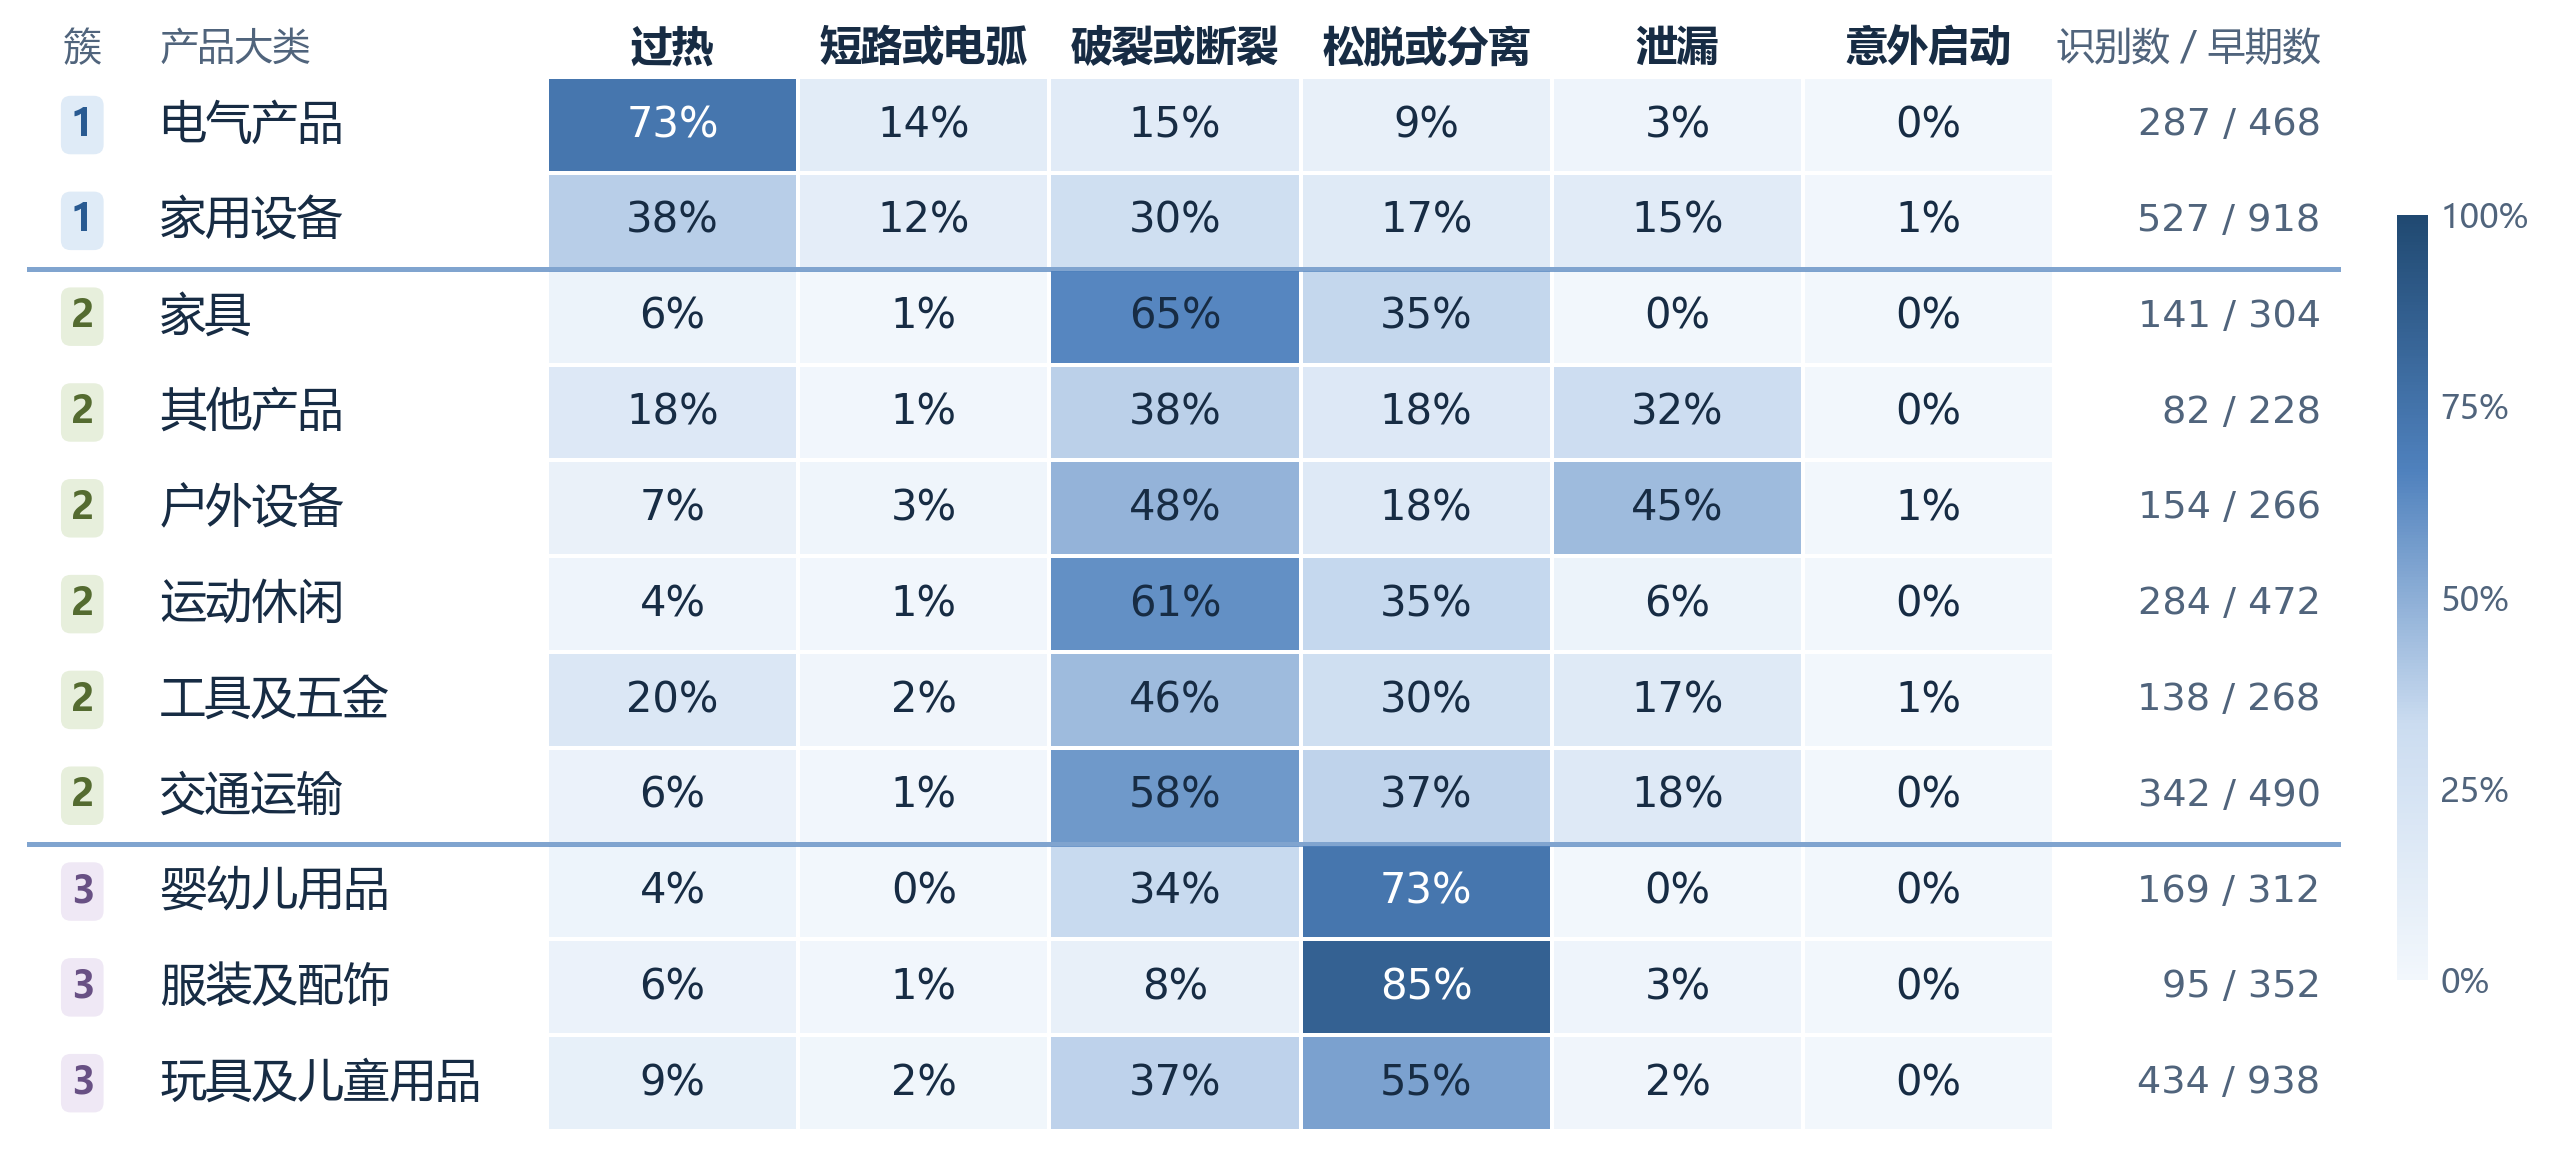

<p style="text-align:center;font-size:.94em">图 1  大类失效比例及分组。方格颜色越深，失效比例越高。</p>

<p style="text-indent:2em;line-height:1.65">家用设备与电气产品聚为一组。服装及配饰、玩具及儿童用品和婴幼儿用品聚为一组。其余六个大类在第三组。这里的同簇关系由六类关键词比例决定，组内可包含结构和使用情境差异较大的产品。</p>

<p style="text-indent:2em;line-height:1.65">K 取 2、3、4、5 时，平均轮廓系数依次为 0.357、0.413、0.389、0.349[4]。平均连接层次聚类和将比例分母改为本类全部早期召回，均得到与主实验相同的三簇分组，调整兰德指数（ARI）均为 1.000。两项敏感性对照的预测与主 B 一致。将 K 改为 2 后，B 的 micro-F1 为 0.365。</p>

## 6 后期结果与案例解释

<p style="text-indent:2em;line-height:1.65">先比较两套方法给出的危险是否覆盖后期召回的实际标签，再检查 A、B 都只给两项提示时，结论是否一致。表 5 前三行采用 0.15 阈值与至少两项的输出规则，后两行为固定两项的对照。</p>

<p style="text-align:center;font-size:.94em">表 5  后期危险预测及固定两项对照</p>

<table style="border-collapse:collapse;width:100%;margin:auto;font-size:.95em">
<thead>
<tr>
<th style="background-color:#416DA3;color:#FFFFFF;text-align:left;width:21.46%;border:1px solid #D2DEEB;padding:6px 8px">方法</th>
<th style="background-color:#416DA3;color:#FFFFFF;text-align:center;width:17.74%;border:1px solid #D2DEEB;padding:6px 8px">命中记录</th>
<th style="background-color:#416DA3;color:#FFFFFF;text-align:center;width:17.44%;border:1px solid #D2DEEB;padding:6px 8px">记录命中率</th>
<th style="background-color:#416DA3;color:#FFFFFF;text-align:center;width:12.37%;border:1px solid #D2DEEB;padding:6px 8px">精确率</th>
<th style="background-color:#416DA3;color:#FFFFFF;text-align:center;width:15.79%;border:1px solid #D2DEEB;padding:6px 8px">标签召回率</th>
<th style="background-color:#416DA3;color:#FFFFFF;text-align:center;width:15.20%;border:1px solid #D2DEEB;padding:6px 8px">micro-F1</th>
</tr>
</thead>
<tbody>
<tr>
<td style="background-color:#E8EFF8;color:#111827;text-align:left;width:21.46%;border:1px solid #D2DEEB;padding:6px 8px">全局频率</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:17.74%;border:1px solid #D2DEEB;padding:6px 8px">710/1,491</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:17.44%;border:1px solid #D2DEEB;padding:6px 8px">47.6%</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:12.37%;border:1px solid #D2DEEB;padding:6px 8px">15.9%</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:15.79%;border:1px solid #D2DEEB;padding:6px 8px">47.5%</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:15.20%;border:1px solid #D2DEEB;padding:6px 8px">0.238</td>
</tr>
<tr>
<td style="background-color:#F7FAFD;color:#111827;text-align:left;width:21.46%;border:1px solid #D2DEEB;padding:6px 8px">A 本类历史</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:17.74%;border:1px solid #D2DEEB;padding:6px 8px">1,049/1,491</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:17.44%;border:1px solid #D2DEEB;padding:6px 8px">70.4%</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:12.37%;border:1px solid #D2DEEB;padding:6px 8px">32.2%</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:15.79%;border:1px solid #D2DEEB;padding:6px 8px">70.3%</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:15.20%;border:1px solid #D2DEEB;padding:6px 8px">0.442</td>
</tr>
<tr>
<td style="background-color:#E8EFF8;color:#111827;text-align:left;width:21.46%;border:1px solid #D2DEEB;padding:6px 8px">B 同簇借鉴</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:17.74%;border:1px solid #D2DEEB;padding:6px 8px">921/1,491</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:17.44%;border:1px solid #D2DEEB;padding:6px 8px">61.8%</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:12.37%;border:1px solid #D2DEEB;padding:6px 8px">27.2%</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:15.79%;border:1px solid #D2DEEB;padding:6px 8px">61.8%</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:15.20%;border:1px solid #D2DEEB;padding:6px 8px">0.377</td>
</tr>
<tr>
<td style="background-color:#F7FAFD;color:#111827;text-align:left;width:21.46%;border:1px solid #D2DEEB;padding:6px 8px">A 固定两项</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:17.74%;border:1px solid #D2DEEB;padding:6px 8px">973/1,491</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:17.44%;border:1px solid #D2DEEB;padding:6px 8px">65.3%</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:12.37%;border:1px solid #D2DEEB;padding:6px 8px">32.7%</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:15.79%;border:1px solid #D2DEEB;padding:6px 8px">65.1%</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:15.20%;border:1px solid #D2DEEB;padding:6px 8px">0.435</td>
</tr>
<tr>
<td style="background-color:#E8EFF8;color:#111827;text-align:left;width:21.46%;border:1px solid #D2DEEB;padding:6px 8px">B 固定两项</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:17.74%;border:1px solid #D2DEEB;padding:6px 8px">854/1,491</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:17.44%;border:1px solid #D2DEEB;padding:6px 8px">57.3%</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:12.37%;border:1px solid #D2DEEB;padding:6px 8px">28.7%</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:15.79%;border:1px solid #D2DEEB;padding:6px 8px">57.2%</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:15.20%;border:1px solid #D2DEEB;padding:6px 8px">0.382</td>
</tr>
</tbody></table>

<p style="text-indent:2em;line-height:1.65">固定每条记录只提示两项后，A 比 B 多命中 119 条，micro-F1 分别为 0.435 和 0.382。因此，在相同清单长度下，优先使用本类历史能覆盖更多后期召回。</p>

<p style="text-indent:2em;line-height:1.65">图 2 先用各大类自己的后期记录数计算命中率。再让 11 个大类各占相同权重，取这些命中率的平均值，A 为 70.0%，B 为 58.4%。因此，A 的优势在大类等权的口径下也成立。</p>

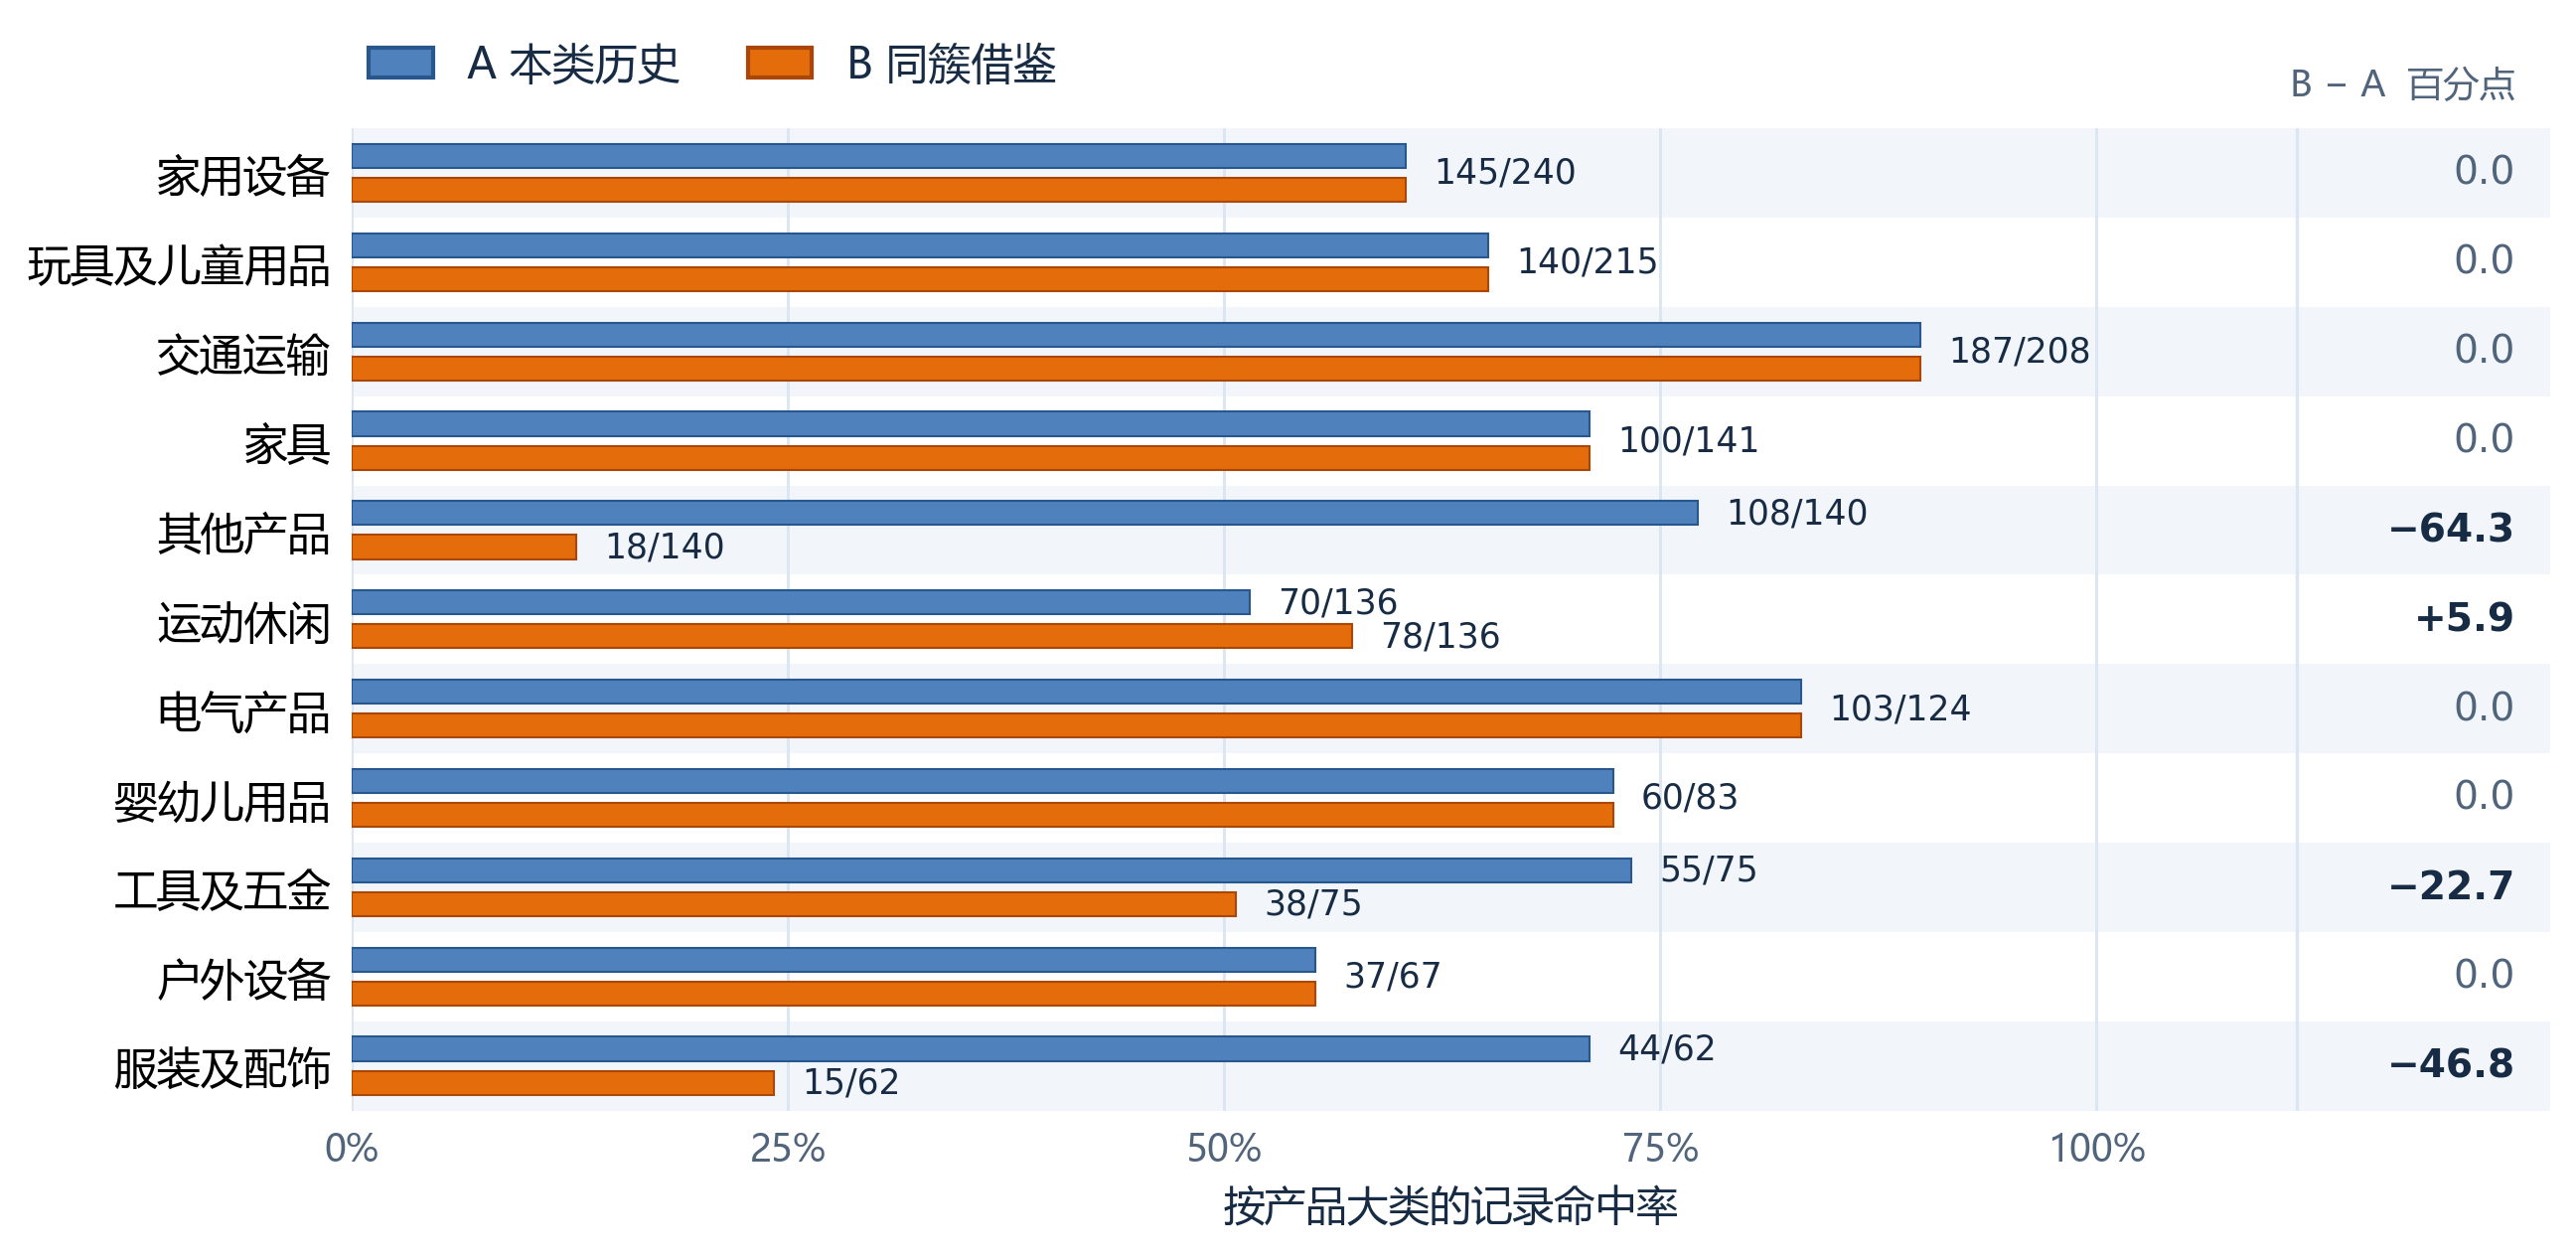

<p style="text-align:center;font-size:.94em">图 2  各产品大类的后期命中率。条旁为命中数 / 评价数，右列为命中率之差。</p>

### 6.1 同簇经验怎样改变提示

<p style="text-align:center;font-size:.94em">表 6  同簇借鉴改变提示的产品大类</p>

<table style="border-collapse:collapse;width:100%;margin:auto;font-size:.95em">
<thead>
<tr>
<th style="background-color:#416DA3;color:#FFFFFF;text-align:left;width:21.91%;border:1px solid #D2DEEB;padding:6px 8px">产品大类</th>
<th style="background-color:#416DA3;color:#FFFFFF;text-align:center;width:26.97%;border:1px solid #D2DEEB;padding:6px 8px">A 提示</th>
<th style="background-color:#416DA3;color:#FFFFFF;text-align:center;width:30.40%;border:1px solid #D2DEEB;padding:6px 8px">B 提示</th>
<th style="background-color:#416DA3;color:#FFFFFF;text-align:center;width:20.72%;border:1px solid #D2DEEB;padding:6px 8px">命中数变化</th>
</tr>
</thead>
<tbody>
<tr>
<td style="background-color:#E8EFF8;color:#111827;text-align:left;width:21.91%;border:1px solid #D2DEEB;padding:6px 8px">其他产品</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:26.97%;border:1px solid #D2DEEB;padding:6px 8px">火灾、中毒</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:30.40%;border:1px solid #D2DEEB;padding:6px 8px">火灾、跌落</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:20.72%;border:1px solid #D2DEEB;padding:6px 8px">108 → 18 / 140</td>
</tr>
<tr>
<td style="background-color:#F7FAFD;color:#111827;text-align:left;width:21.91%;border:1px solid #D2DEEB;padding:6px 8px">服装及配饰</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:26.97%;border:1px solid #D2DEEB;padding:6px 8px">窒息或噎塞、灼伤</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:30.40%;border:1px solid #D2DEEB;padding:6px 8px">窒息或噎塞、跌落</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:20.72%;border:1px solid #D2DEEB;padding:6px 8px">44 → 15 / 62</td>
</tr>
<tr>
<td style="background-color:#E8EFF8;color:#111827;text-align:left;width:21.91%;border:1px solid #D2DEEB;padding:6px 8px">工具及五金</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:26.97%;border:1px solid #D2DEEB;padding:6px 8px">割伤、火灾、撞击伤害</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:30.40%;border:1px solid #D2DEEB;padding:6px 8px">火灾、割伤、跌落</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:20.72%;border:1px solid #D2DEEB;padding:6px 8px">55 → 38 / 75</td>
</tr>
<tr>
<td style="background-color:#F7FAFD;color:#111827;text-align:left;width:21.91%;border:1px solid #D2DEEB;padding:6px 8px">运动休闲</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:26.97%;border:1px solid #D2DEEB;padding:6px 8px">跌落、撞击伤害</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:30.40%;border:1px solid #D2DEEB;padding:6px 8px">跌落、撞击伤害、火灾</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:20.72%;border:1px solid #D2DEEB;padding:6px 8px">70 → 78 / 136</td>
</tr>
</tbody></table>

<p style="text-indent:2em;line-height:1.65">其他产品是命中降幅最大的大类。该类有 91 个后期中毒标签。同簇平均把中毒从 0.180 降到 0.100，将跌落推至 0.155，导致提示由中毒改为跌落。2019 年编号 8499 的原始记录描述儿童可能接触局部麻醉凝胶，标注中毒。A 命中，B 漏报。即使从后期样本剔除异质性较强的其他产品，A 仍命中 941/1,351，B 命中 903/1,351。</p>

<p style="text-indent:2em;line-height:1.65">运动休闲是同簇借鉴带来收益的例子。借鉴后火灾得分从 0.032 升至 0.161，成为第三个提示，同时保留跌落和撞击伤害。后期多命中 8 条，其中编号 8931 涉及运动计时器电池过热，标注火灾。这个例子说明同簇信息可补入本类历史中较少见的危险，也需要按大类验证加入后会替代或增加哪些提示。</p>

### 6.2 后期漏报集中在哪些危险

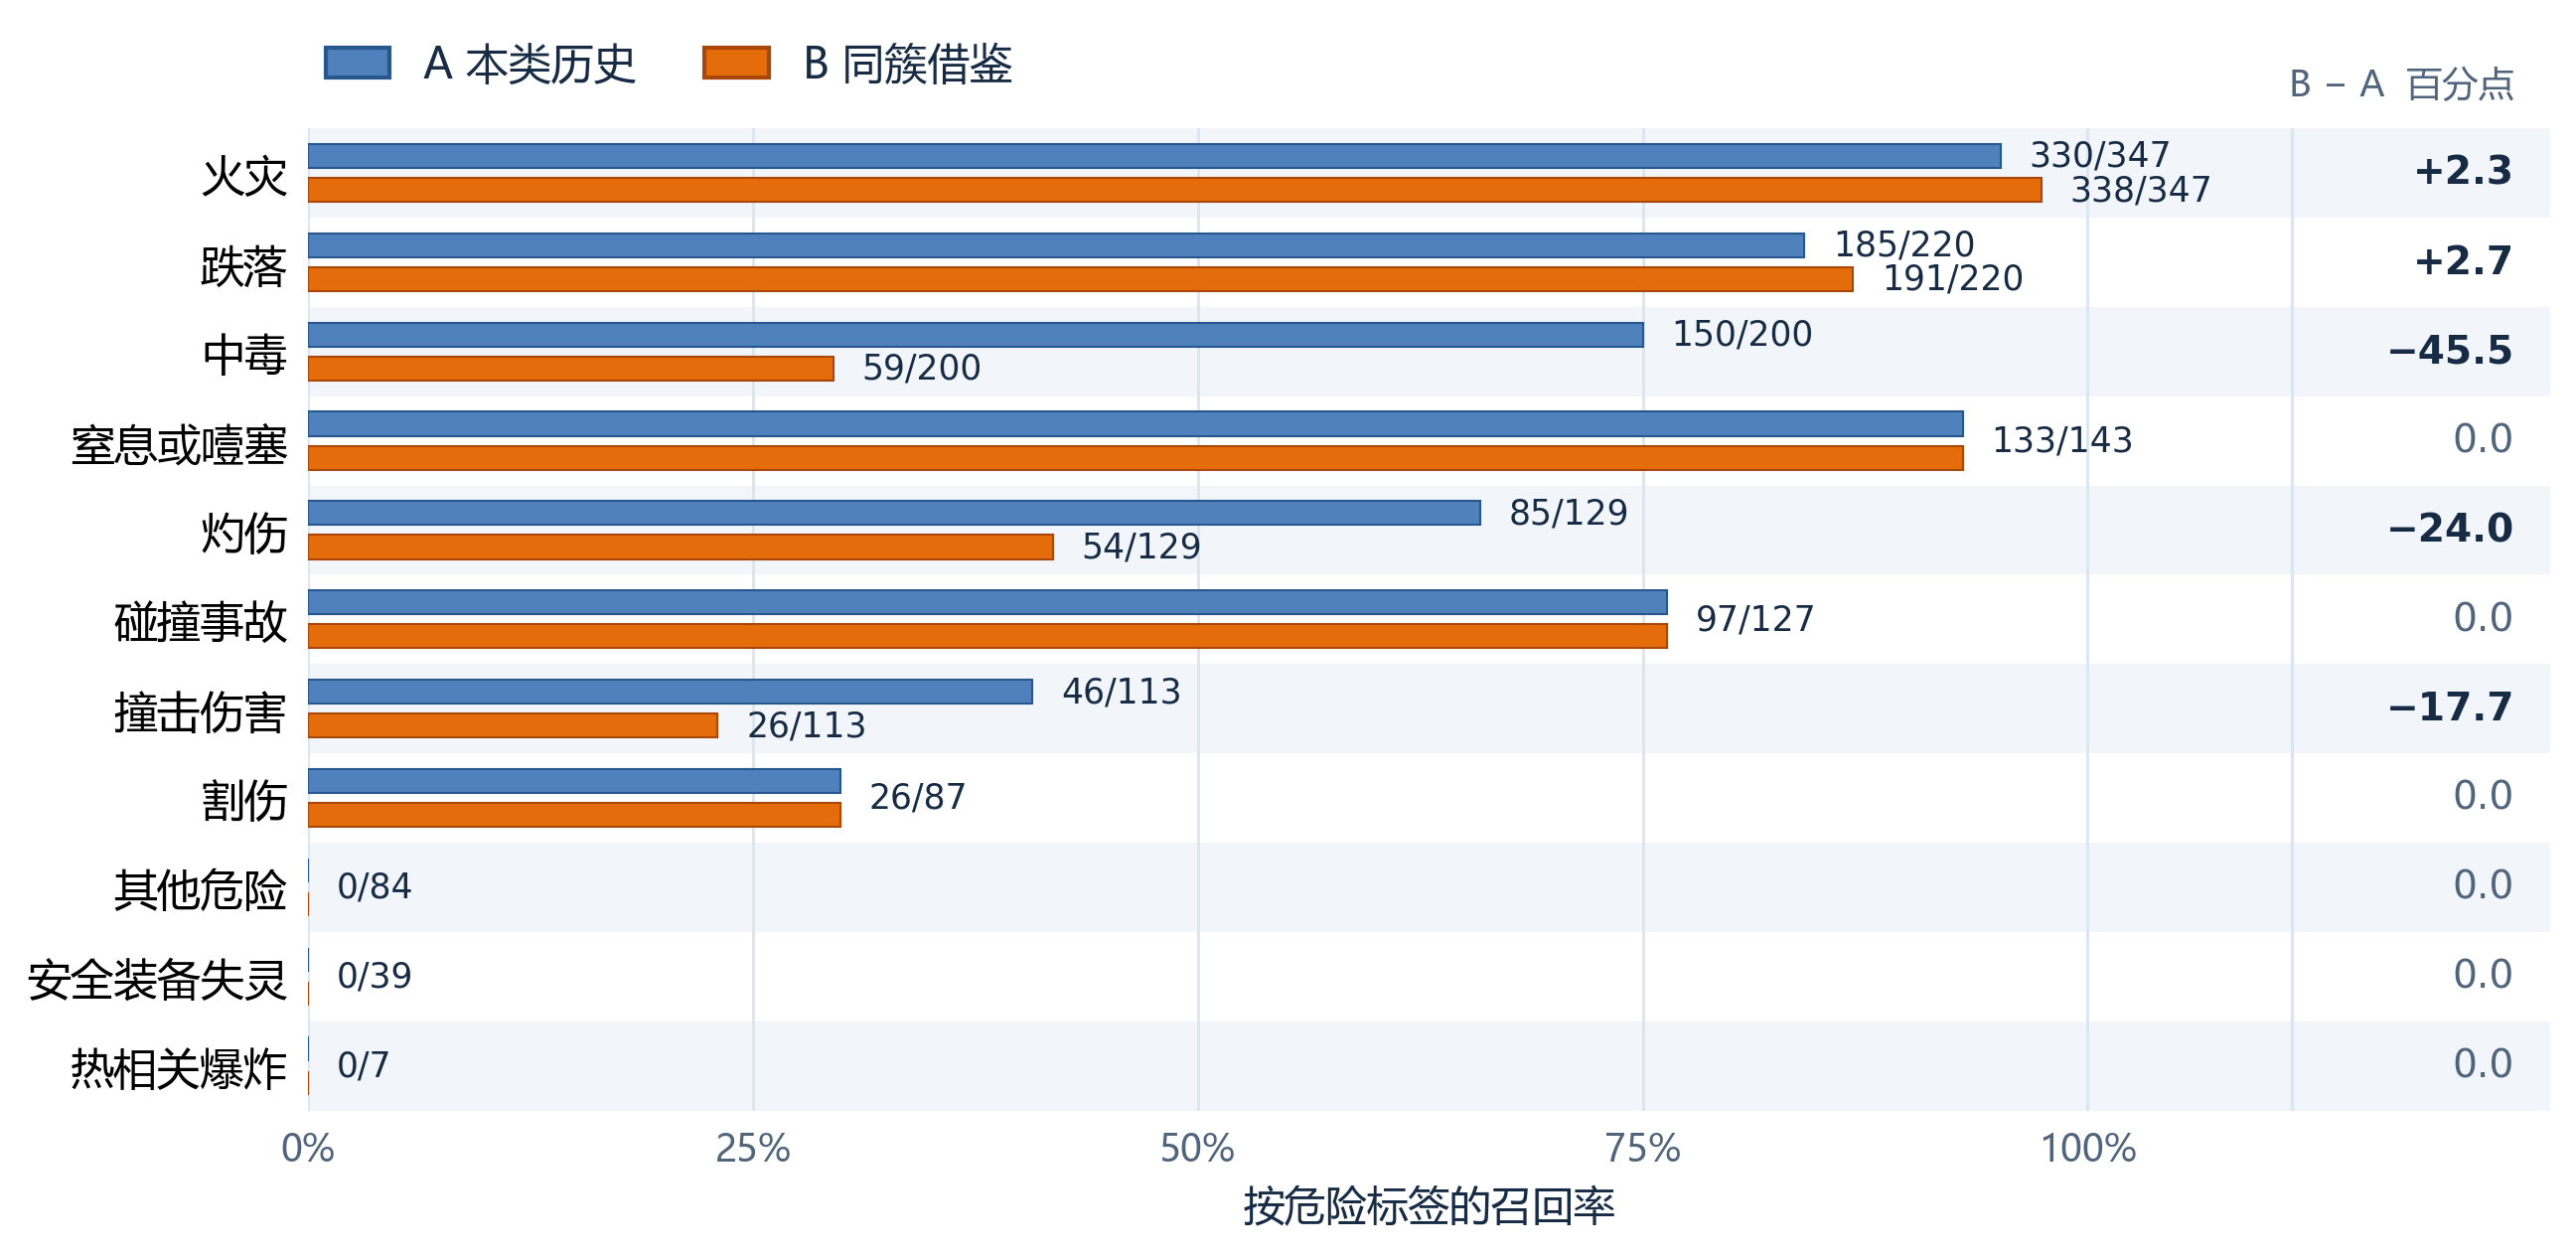

<p style="text-align:center;font-size:.94em">图 3  各危险标签的召回率。条旁为正确提示数 / 标签数，右列为召回率之差。</p>

<p style="text-indent:2em;line-height:1.65">B 的中毒命中从 150/200 降至 59/200，灼伤从 85/129 降至 54/129，撞击伤害从 46/113 降至 26/113。火灾和跌落标签的命中分别增加 8 次和 6 次。</p>

<p style="text-indent:2em;line-height:1.65">两种方法均未命中 39 个安全装备失灵、7 个热相关爆炸和 84 个其他危险标签。这些漏报反映了用大类频率生成短清单对低排名危险的覆盖限制。</p>

## 7 家用设备子类对照

<p style="text-indent:2em;line-height:1.65">全量大类分析给出不同产品领域的整体规律。若设计师已知正在设计的具体产品，家用设备子类能提供更细的提示。家用设备词典覆盖 15 个预定义子类，筛得 354 起召回。其中 11 个子类满足早期建模条件，对应 73 起后期召回。按召回编号将这 73 起与全量模型的家用设备预测逐条对齐，核对两份记录的真实危险标签完全一致。</p>

<p style="text-align:center;font-size:.94em">表 7  同一批 73 起家用设备召回的大类与子类对照</p>

<table style="border-collapse:collapse;width:100%;margin:auto;font-size:.95em">
<thead>
<tr>
<th style="background-color:#416DA3;color:#FFFFFF;text-align:left;width:35.91%;border:1px solid #D2DEEB;padding:6px 8px">预测依据</th>
<th style="background-color:#416DA3;color:#FFFFFF;text-align:center;width:22.65%;border:1px solid #D2DEEB;padding:6px 8px">命中事件</th>
<th style="background-color:#416DA3;color:#FFFFFF;text-align:center;width:20.72%;border:1px solid #D2DEEB;padding:6px 8px">事件命中率</th>
<th style="background-color:#416DA3;color:#FFFFFF;text-align:center;width:20.72%;border:1px solid #D2DEEB;padding:6px 8px">micro-F1</th>
</tr>
</thead>
<tbody>
<tr>
<td style="background-color:#E8EFF8;color:#111827;text-align:left;width:35.91%;border:1px solid #D2DEEB;padding:6px 8px">家用设备大类 A</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:22.65%;border:1px solid #D2DEEB;padding:6px 8px">45/73</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:20.72%;border:1px solid #D2DEEB;padding:6px 8px">61.6%</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:20.72%;border:1px solid #D2DEEB;padding:6px 8px">0.411</td>
</tr>
<tr>
<td style="background-color:#F7FAFD;color:#111827;text-align:left;width:35.91%;border:1px solid #D2DEEB;padding:6px 8px">家用设备大类 B</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:22.65%;border:1px solid #D2DEEB;padding:6px 8px">45/73</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:20.72%;border:1px solid #D2DEEB;padding:6px 8px">61.6%</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:20.72%;border:1px solid #D2DEEB;padding:6px 8px">0.411</td>
</tr>
<tr>
<td style="background-color:#E8EFF8;color:#111827;text-align:left;width:35.91%;border:1px solid #D2DEEB;padding:6px 8px">家用设备子类 A</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:22.65%;border:1px solid #D2DEEB;padding:6px 8px">57/73</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:20.72%;border:1px solid #D2DEEB;padding:6px 8px">78.1%</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:20.72%;border:1px solid #D2DEEB;padding:6px 8px">0.502</td>
</tr>
<tr>
<td style="background-color:#F7FAFD;color:#111827;text-align:left;width:35.91%;border:1px solid #D2DEEB;padding:6px 8px">家用设备子类 B</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:22.65%;border:1px solid #D2DEEB;padding:6px 8px">56/73</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:20.72%;border:1px solid #D2DEEB;padding:6px 8px">76.7%</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:20.72%;border:1px solid #D2DEEB;padding:6px 8px">0.511</td>
</tr>
</tbody></table>

<p style="text-indent:2em;line-height:1.65">大类模型对这 73 起事件均提示火灾和灼伤。子类模型可以为锅炉提示中毒和火灾，贴合锅炉历史中较高的中毒比例（10/15），同时保留取暖器的火灾与灼伤提示。A 按子类预测多覆盖 12 起。B 在家电小类中少命中 1 起，但提示较少，micro-F1 略升。在每起都只给两条提示的比较中，小类 A 和 B 的 micro-F1 分别为 0.521 和 0.511。</p>

<p style="text-indent:2em;line-height:1.65">这项对照评估的是现有两种粒度下可用的历史预测。小类模型由已识别的家电事件建模，大类模型使用更广的家电历史。结论适用于这批能够识别子类且有足够早期记录的家用设备召回。</p>

### 7.1 空调及热泵的设计复查示例

<p style="text-indent:2em;line-height:1.65">空调及热泵早期的 17 起召回中，15 起标注火灾，2 起标注灼伤。实验 A 优先提示火灾，补入灼伤，实验 B 给出相同的两项提示。评审空调时，可回查对应公告中的部件和失效过程，形成表 8 的复查问题。</p>

<p style="text-align:center;font-size:.94em">表 8  空调及热泵的历史案例与复查问题</p>

<table style="border-collapse:collapse;width:100%;margin:auto;font-size:.95em">
<thead>
<tr>
<th style="background-color:#416DA3;color:#FFFFFF;text-align:left;width:15.20%;border:1px solid #D2DEEB;padding:6px 8px">危险</th>
<th style="background-color:#416DA3;color:#FFFFFF;text-align:center;width:39.49%;border:1px solid #D2DEEB;padding:6px 8px">案例依据</th>
<th style="background-color:#416DA3;color:#FFFFFF;text-align:center;width:45.31%;border:1px solid #D2DEEB;padding:6px 8px">相似结构的复查问题</th>
</tr>
</thead>
<tbody>
<tr>
<td style="background-color:#E8EFF8;color:#111827;text-align:left;width:15.20%;border:1px solid #D2DEEB;padding:6px 8px">火灾</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:39.49%;border:1px solid #D2DEEB;padding:6px 8px">编号 7984。公告描述电源线插头过热。</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:45.31%;border:1px solid #D2DEEB;padding:6px 8px">电源插头及其连接处在预期工况下的温升是否已复查？</td>
</tr>
<tr>
<td style="background-color:#F7FAFD;color:#111827;text-align:left;width:15.20%;border:1px solid #D2DEEB;padding:6px 8px">火灾</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:39.49%;border:1px solid #D2DEEB;padding:6px 8px">编号 448。公告描述冷凝水接触控制板，引起短路。</td>
<td style="background-color:#F7FAFD;color:#111827;text-align:center;width:45.31%;border:1px solid #D2DEEB;padding:6px 8px">冷凝水的排水路径是否与控制板隔离？</td>
</tr>
<tr>
<td style="background-color:#E8EFF8;color:#111827;text-align:left;width:15.20%;border:1px solid #D2DEEB;padding:6px 8px">灼伤</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:39.49%;border:1px solid #D2DEEB;padding:6px 8px">编号 8269。室外风机电机过热。</td>
<td style="background-color:#E8EFF8;color:#111827;text-align:center;width:45.31%;border:1px solid #D2DEEB;padding:6px 8px">风机电机的温升与周边可接触表面的温度是否已复查？</td>
</tr>
</tbody></table>

<p style="text-indent:2em;line-height:1.65">表 8 的复查问题来自具体公告，适用于具有相近结构和使用条件的产品。第 6 节的评价指标衡量危险标签的历史覆盖度。</p>

## 8 实验 D 可见结构与危险的全期关联

### 8.1 研究问题与方法

以设计师已知的产品类别、可见结构和实验 A、B 的危险提示为输入，查找同类历史召回中同时提到该结构和危险的案例。实验 D 使用 2000–2024 年全期召回进行描述性关联分析。日期用于保留案例来源，A、B 的时间验证用于回答危险提示的预测表现。

RECALL-MM 的 `visual_product_description` 由模型根据产品图像生成[1]。本实验从中提取九类结构，如门盖、折叠铰链和外部电源线。先过滤含明显危险或召回措辞的句子，未提到的结构记为缺少证据。对同一召回编号和产品类别，每个组合只计一次。结构与危险标签须在至少一条同类别原始记录中共同出现。`recall_description` 用于核对具体失效过程。

挖掘的规则为「同一类别＋可见结构 → 危险标签」。至少 5 起记录提到该结构、至少 3 起共现才展示。置信度为共现次数除以提到结构的次数。提升度为置信度除以本类全部召回中该危险的比例。整理完所有规则后，标出与 A 或 B 提示一致的危险；设计师输入结构后，可以按类别、结构和 A/B 提示查找规则并查看召回编号。

### 8.2 全期结果与复查示例

<p style="text-align:center;font-size:.94em">表 9  全期外观规则的覆盖与支持度检查</p>
<table style="border-collapse:collapse;width:100%;margin:auto;font-size:.95em">
<tr>
<th style="background-color:#416DA3;color:#FFFFFF;border:1px solid #D2DEEB;text-align:left;padding:6px 8px">分析范围</th>
<th style="background-color:#416DA3;color:#FFFFFF;border:1px solid #D2DEEB;text-align:center;padding:6px 8px">召回记录¹</th>
<th style="background-color:#416DA3;color:#FFFFFF;border:1px solid #D2DEEB;text-align:center;padding:6px 8px">类别数</th>
<th style="background-color:#416DA3;color:#FFFFFF;border:1px solid #D2DEEB;text-align:center;padding:6px 8px">识别到结构</th>
<th style="background-color:#416DA3;color:#FFFFFF;border:1px solid #D2DEEB;text-align:center;padding:6px 8px">全部规则</th>
<th style="background-color:#416DA3;color:#FFFFFF;border:1px solid #D2DEEB;text-align:center;padding:6px 8px">与 A/B 对应</th>
<th style="background-color:#416DA3;color:#FFFFFF;border:1px solid #D2DEEB;text-align:center;padding:6px 8px">共现至少 5 起²</th>
</tr>
<tr>
<td style="background-color:#E8EFF8;color:#111827;border:1px solid #D2DEEB;text-align:left;padding:6px 8px">全量产品大类</td>
<td style="background-color:#E8EFF8;color:#111827;border:1px solid #D2DEEB;text-align:center;padding:6px 8px">6,507</td>
<td style="background-color:#E8EFF8;color:#111827;border:1px solid #D2DEEB;text-align:center;padding:6px 8px">11</td>
<td style="background-color:#E8EFF8;color:#111827;border:1px solid #D2DEEB;text-align:center;padding:6px 8px">2,449（37.6%）</td>
<td style="background-color:#E8EFF8;color:#111827;border:1px solid #D2DEEB;text-align:center;padding:6px 8px">195</td>
<td style="background-color:#E8EFF8;color:#111827;border:1px solid #D2DEEB;text-align:center;padding:6px 8px">102</td>
<td style="background-color:#E8EFF8;color:#111827;border:1px solid #D2DEEB;text-align:center;padding:6px 8px">84</td>
</tr>
<tr>
<td style="background-color:#F7FAFD;color:#111827;border:1px solid #D2DEEB;text-align:left;padding:6px 8px">家用设备子类</td>
<td style="background-color:#F7FAFD;color:#111827;border:1px solid #D2DEEB;text-align:center;padding:6px 8px">354</td>
<td style="background-color:#F7FAFD;color:#111827;border:1px solid #D2DEEB;text-align:center;padding:6px 8px">15</td>
<td style="background-color:#F7FAFD;color:#111827;border:1px solid #D2DEEB;text-align:center;padding:6px 8px">185（52.3%）</td>
<td style="background-color:#F7FAFD;color:#111827;border:1px solid #D2DEEB;text-align:center;padding:6px 8px">23</td>
<td style="background-color:#F7FAFD;color:#111827;border:1px solid #D2DEEB;text-align:center;padding:6px 8px">18</td>
<td style="background-color:#F7FAFD;color:#111827;border:1px solid #D2DEEB;text-align:center;padding:6px 8px">14</td>
</tr>
</table>

¹ 大类按召回编号与产品大类组合计数，家电小类按召回编号计数。² 将共现门槛从 3 起提高到 5 起后，仍对应 A 或 B 的规则数。

全量大类有 6,304 个组合包含非空外观文本，家电小类有 339 起。有限词典只在其中一部分记录识别到指定结构。15 个家电小类都用于历史统计，其中 11 个有 A、B 提示可作对照。

<p style="text-align:center;font-size:.94em">表 10  经公告原文核对的外观规则示例</p>
<table style="border-collapse:collapse;width:100%;margin:auto;font-size:.95em">
<tr>
<th style="background-color:#416DA3;color:#FFFFFF;border:1px solid #D2DEEB;text-align:left;padding:6px 8px">产品子类</th>
<th style="background-color:#416DA3;color:#FFFFFF;border:1px solid #D2DEEB;text-align:center;padding:6px 8px">可见结构</th>
<th style="background-color:#416DA3;color:#FFFFFF;border:1px solid #D2DEEB;text-align:center;padding:6px 8px">A/B 危险</th>
<th style="background-color:#416DA3;color:#FFFFFF;border:1px solid #D2DEEB;text-align:center;padding:6px 8px">共现 / 提到结构</th>
<th style="background-color:#416DA3;color:#FFFFFF;border:1px solid #D2DEEB;text-align:center;padding:6px 8px">提升度</th>
<th style="background-color:#416DA3;color:#FFFFFF;border:1px solid #D2DEEB;text-align:center;padding:6px 8px">历史案例与复查</th>
</tr>
<tr>
<td style="background-color:#E8EFF8;color:#111827;border:1px solid #D2DEEB;text-align:left;padding:6px 8px">冰箱及冷柜</td>
<td style="background-color:#E8EFF8;color:#111827;border:1px solid #D2DEEB;text-align:center;padding:6px 8px">门或可开启盖</td>
<td style="background-color:#E8EFF8;color:#111827;border:1px solid #D2DEEB;text-align:center;padding:6px 8px">撞击伤害</td>
<td style="background-color:#E8EFF8;color:#111827;border:1px solid #D2DEEB;text-align:center;padding:6px 8px">5/16</td>
<td style="background-color:#E8EFF8;color:#111827;border:1px solid #D2DEEB;text-align:center;padding:6px 8px">0.98</td>
<td style="background-color:#E8EFF8;color:#111827;border:1px solid #D2DEEB;text-align:center;padding:6px 8px">编号 9318。铰链断裂后门体脱落。具有类似结构的设计可复查开关门时的铰链和门体连接。</td>
</tr>
<tr>
<td style="background-color:#F7FAFD;color:#111827;border:1px solid #D2DEEB;text-align:left;padding:6px 8px">空调及热泵</td>
<td style="background-color:#F7FAFD;color:#111827;border:1px solid #D2DEEB;text-align:center;padding:6px 8px">通风孔或格栅</td>
<td style="background-color:#F7FAFD;color:#111827;border:1px solid #D2DEEB;text-align:center;padding:6px 8px">火灾</td>
<td style="background-color:#F7FAFD;color:#111827;border:1px solid #D2DEEB;text-align:center;padding:6px 8px">11/12</td>
<td style="background-color:#F7FAFD;color:#111827;border:1px solid #D2DEEB;text-align:center;padding:6px 8px">1.11</td>
<td style="background-color:#F7FAFD;color:#111827;border:1px solid #D2DEEB;text-align:center;padding:6px 8px">编号 7984。该案例实际描述电源插头过热。若待评审设计也有类似插头，可核对其连接处的温升。</td>
</tr>
</table>

单看冰箱及冷柜的门体规则，撞击伤害置信度为 31.25%，接近本类总体的 31.82%。规则能帮助找到门体相关先例，复查铰链的依据来自公告。空调格栅规则有 11 起火灾共现。案例 7984 的过热部位是插头。这个例子说明，外观匹配后仍需核对公告记录的失效部位。

[CPSC 冰箱门铰链召回原公告](https://www.cpsc.gov/Recalls/2022/Hisense-USA-Recalls-Bottom-Freezer-French-Door-Refrigerators-Due-to-Impact-Injury-Hazard-Sold-Exclusively-at-Lowes)  [CPSC 空调插头过热召回原公告](https://www.cpsc.gov/id/Recalls/2017/carrier-expands-recall-of-packaged-terminal-air-conditioners-and-heat-pumps)

### 8.3 解读与复查条件

D 的比例以已经召回且提到该结构的历史记录为分母。外观文本和类别标签来自数据集整理，结构没被词典提取时无法判断实际有无。规则给出可追溯的案例线索；形成部件复查建议时，需确认公告涉及的结构和失效过程适用于新设计。缺少外观依据时，沿用 A、B 的危险提示。同类与同结构支持案例越少，结果越依赖个别公告。

## 9 讨论与结论

<p style="text-indent:2em;line-height:1.65">在全量评价中，本类历史的命中率和 micro-F1 均高于同簇等权借鉴。跨类借鉴带来 14 条独有命中，同时压低了部分本类危险的排名。设计复查可从本类提示出发，再针对具体失效方式查找跨类先例。</p>

<p style="text-indent:2em;line-height:1.65">家用设备子类对照提供了比大类更细的历史提示。六类失效关键词在全量数据中约覆盖一半记录，匹配可能存在歧义。召回记录缺少在售数量和使用暴露量，得分反映这些召回中的标签频率。</p>

全期实验 D 用外观结构与危险的共现规则为 A、B 提示补充历史案例。设计评审中的具体核对项应追溯到公告的失效过程，并结合待评审产品的结构。

## 参考文献

[1] Bolanos D, Ataei M, Grandi D, Goucher-Lambert K. RECALL-MM. arXiv:2503.23213, 2025.

[2] Agrawal R, Srikant R. Fast Algorithms for Mining Association Rules. VLDB, 1994, 487–499.

[3] Arthur D, Vassilvitskii S. k-means++: The Advantages of Careful Seeding. SODA, 2007, 1027–1035.

[4] Rousseeuw P J. Silhouettes. Journal of Computational and Applied Mathematics, 1987, 20, 53–65.

**复现** 文末的代码附录从原始 `dataset.json` 重新计算正文结果。

## 代码附录

正文沿用 Word 报告的图表和 A、B 实验，另加入实验 D。代码从同一份原始 JSON 重算全量及家用设备 A、B，复查三张图，并生成全期外观规则和设计复查示例。

可直接从项目里的 Notebook 运行。单独使用时，把 `dataset.json` 放在 Notebook 所在目录，或在下方设置 `DATA_PATH`。需要 Python 及 `numpy`、`scikit-learn`、`threadpoolctl`、`matplotlib`，并使用 Jupyter 的 Python 内核。重新生成中文图时，请使用已安装的中文字体。

### A.1 加载原始数据

核对原始记录数。查找文件时也接受微信附件的文件名 `dataset(1).json`。

In [1]:
from collections import Counter, defaultdict
from fractions import Fraction
import hashlib
from io import BytesIO
from itertools import combinations
import json
from pathlib import Path
import re
from statistics import mean

import numpy as np
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from threadpoolctl import threadpool_limits

DATA_PATH = None  # 需要时填写 Path("/path/to/dataset.json")
base = Path.cwd()
candidates = [base / "dataset.json", base / "dataset(1).json",
              base / "recall_study_2026" / "dataset.json",
              base.parent / "recall_study_2026" / "dataset.json"]
if DATA_PATH is None:
    DATA_PATH = next((path for path in candidates if path.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError("未找到 dataset.json。请放在 Notebook 所在目录或填写 DATA_PATH。")
DATA_PATH = Path(DATA_PATH)
raw_bytes = DATA_PATH.read_bytes()
raw = json.loads(raw_bytes)
assert len(raw) == 6874
print(f"原始记录：{len(raw):,} 条，{len({row['recall_number'] for row in raw}):,} 个召回编号")

原始记录：6,874 条，6,464 个召回编号


### A.2 预处理与失效特征

用原实验的六类关键词生成失效特征。大类以召回编号与大类组合为单位，家电子类使用原名称词典。

In [2]:
TYPES = {
    '热水器': r'water heaters?',
    '锅炉': r'boilers?',
    '壁炉': r'fireplaces?',
    '暖炉': r'furnaces?',
    '取暖器': r'heaters?',
    '空调及热泵': r'air conditioners?|heat pumps?',
    '除湿机': r'dehumidifiers?',
    '冰箱及冷柜': r'refrigerators?|freezers?',
    '洗碗机': r'dishwashers?',
    '洗衣机': r'washing machines?|clothes washers?',
    '咖啡及浓缩咖啡设备': r'coffee\s?(?:makers?|brewers?|machines?|centers?)|espresso (?:makers?|machines?)',
    '压力锅': r'pressure cookers?',
    '灶具及烤箱': r'ranges?|ovens?|cooktops?',
    '风扇': r'fans?',
    '吸尘器': r'vacuums?',
}


MODES = {
    '过热': r'overheat(?:s|ed|ing)?',
    '电气短路或电弧': r'short[- ]circuit(?:s|ed|ing)?|(?:electrical|electric) shorts?|arc(?:ing|s)',
    '破裂或断裂': r'break(?:s|ing)?|broken|crack(?:s|ed|ing)?|shatter(?:s|ed|ing)?|fracture(?:s|d)?',
    '松脱或分离': r'detach(?:es|ed|ing)?|separat(?:e|es|ed|ing)|(?:come|comes|become|becomes) loose|loosen(?:s|ed|ing)?|fall off',
    '泄漏': r'leak(?:s|ed|ing|age)?',
    '意外启动': r'(?:turn on|activate|start) (?:unexpectedly|unintentionally|by itself)|(?:unintentionally|unexpectedly) (?:turn on|activate|start)',
}


MODES['过热'] += r'|(?:get|gets|become) too hot|temperatures? (?:exceeds? allowable|can get too high)|elevated internal temperature|temperature of the storage drawer can become extremely high|heat to build up'


MODES['电气短路或电弧'] += r'|(?:electric|electrical) arc|short(?:s|ed)? out'


MODES['破裂或断裂'] += r'|ruptur(?:e|es|ed)|burst(?:s)?'


MODES['松脱或分离'] += r'|pulled loose|dislodg(?:e|es|ed)|detachments?|disengage|fall from (?:its housing|the ceiling|the wall)'


MODES['泄漏'] += r'|(?:flue gas|gas) (?:can|to) escape|gas to be released'


MODES['意外启动'] += r'|turn on (?:by themselves|without user input|spontaneously)|activated by accidental contact'


EXCLUDE = re.compile(
    r'\b(?:range hoods?|oven mitts?|oven gloves?|vacuum flasks?|dutch ovens?|oven liners?|'
    r'oven rack guards?|cooktop fire suppressors?|drip pans?|fire suppression devices?|oven cleaner|'
    r'gas control valves for|water heater (?:gas )?temperature controls?|spas and hot tubs|'
    r'fireplace screens?|fireplace gas valves?|gas valves used in|remote control kits?|'
    r'attachment tools?|fan electric motor|coil drain pans?|boiler (?:operating|control|controller)|'
    r'control units for boilers|service kit|accessory (?:electric )?heaters?|defrost heaters?|'
    r'(?:spa|pool|immersion) heaters?)\b', re.I)


def matches(dictionary, phrase):
    return [name for name, pattern in dictionary.items()
            if re.search(r'\b(?:' + pattern + r')\b', phrase, re.I)]


CATEGORY_NAMES = {
    "HOME_APPLIANCES": "家用设备", "TOYS_CHILDREN": "玩具及儿童用品",
    "TRANSPORTATION": "交通运输", "SPORTS_RECREATION": "运动休闲",
    "ELECTRICAL": "电气产品", "CLOTHING_ACCESSORIES": "服装及配饰",
    "FURNITURE": "家具", "BABY_PRODUCTS": "婴幼儿用品", "OTHER": "其他产品",
    "TOOLS_HARDWARE": "工具及五金", "OUTDOOR_EQUIPMENT": "户外设备",
}


HAZARD_NAMES = {
    "FIRE": "火灾", "FALLING": "跌落", "CHOKING": "窒息或噎塞", "POISONING": "中毒",
    "BURN": "灼伤", "IMPACT": "撞击伤害", "CUTS": "割伤", "CRASH": "碰撞事故",
    "OTHER": "其他危险", "SAFETY_EQUIPMENT_MALFUNCTION": "安全装备失灵",
    "HEAT_RELATED_EXPOLOSION": "热相关爆炸",
}


def prepare(raw):
    """Keep each ID–category pair and merge only its corresponding raw labels."""
    cases = {}
    years = {}
    for row in raw:
        rid = row["recall_number"]
        year = int(row["recall_date"][:4])
        if years.setdefault(rid, year) != year:
            raise ValueError(f"Conflicting years for recall {rid}")
        if not row["product_classification"] or not row["hazard_classification"]:
            raise ValueError(f"Unlabeled row for recall {rid}")
        modes = matches(MODES, row["recall_description"])
        for category in row["product_classification"]:
            pair = (rid, category)
            case = cases.setdefault(pair, {
                "id": rid, "year": year, "subtype": category, "hazards": set(), "modes": set(),
                "raw_entries": [],
            })
            case["hazards"].update(row["hazard_classification"])
            case["modes"].update(modes)
            case["raw_entries"].append({
                "product": row["product_name"], "description": row["recall_description"],
                "hazards": row["hazard_classification"],
            })
    assert sum(len(case["raw_entries"]) for case in cases.values()) == len(raw)
    return list(cases.values())


def partition(cases):
    groups = defaultdict(list)
    for case in cases:
        groups[case["subtype"]].append(case)
    return groups


def unique_count(cases):
    return len({case["id"] for case in cases})


def hazards_per_recall(cases):
    result = defaultdict(set)
    for case in cases:
        result[case["id"]].update(case["hazards"])
    return result

### A.3 Apriori 与 K-means 的计算函数

Apriori 提取单危险规则，K-means 确定参考类别。两套预测都用相同阈值和同一后期评价口径。

In [3]:
THRESHOLD = Fraction(15, 100)


DISPLAY_MIN = 5


def apriori(rows, min_support):
    """Compute frequent 1- and 2-itemsets, with event-level support."""
    baskets = [
        (r["id"], frozenset([("family", r["subtype"]), *(("hazard", h) for h in r["hazards"])]))
        for r in rows
    ]
    item_events = {
        item: {i for i, basket in baskets if item in basket}
        for item in sorted(set().union(*(basket for _, basket in baskets)))
    }
    singles = [item for item, ids in item_events.items() if len(ids) >= min_support]
    pairs = {}
    for x, y in combinations(singles, 2):
        pair_ids = {i for i, basket in baskets if x in basket and y in basket}
        if len(pair_ids) >= min_support:
            pairs[x, y] = pair_ids
    rules = {(x[1], y[1]): len(ids) for (x, y), ids in pairs.items()
             if x[0] == "family" and y[0] == "hazard"}
    return rules, {"singles": len(singles), "pairs_tested": len(singles)*(len(singles)-1)//2,
                   "frequent_pairs": len(pairs)}


def eligible_families(groups):
    return [t for t, events in groups.items()
            if len(events) >= 10 and sum(bool(r["modes"]) for r in events) >= 5]


def hazard_rates(events, hazards):
    return {h: Fraction(sum(h in r["hazards"] for r in events), len(events)) for h in hazards}


def choose(scores, global_count, threshold):
    order = sorted(scores, key=lambda h: (-scores[h], -global_count[h], h))
    above = [h for h in order if scores[h] >= threshold]
    return (above if len(above) >= 2 else order[:2]), above


def measure(test, predictions, labels):
    counts = {h: Counter() for h in labels}
    matched = prompts = extras = 0
    for r in test:
        pred = set(predictions[r["subtype"]])
        actual = r["hazards"]
        matched += bool(pred & actual)
        prompts += len(pred)
        extras += len(pred) > 2
        for h in labels:
            counts[h]["tp" if h in pred and h in actual else
                      "fp" if h in pred else "fn" if h in actual else "tn"] += 1
    totals = sum(counts.values(), Counter())

    def rates(c):
        tp, fp, fn = (c[k] for k in ("tp", "fp", "fn"))
        return {
            **{key:c[key] for key in ("tp","fp","fn","tn")}, "n_ref": tp+fn,
            "precision": tp/(tp+fp) if tp+fp else None,
            "recall": tp/(tp+fn) if tp+fn else None,
            "f1": 2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else None,
        }

    return {
        **rates(totals), "n": len(test), "hit": matched, "hit_rate": matched/len(test),
        "prompts": prompts, "average_prompts": prompts/len(test), "extra_events": extras,
        "metrics_by_hazard": {h: rates(c) for h, c in counts.items()},
    }


def fit_clusters(x, k):
    return KMeans(n_clusters=k, init="k-means++", n_init=50, random_state=42).fit(x)


def scores_for_groups(names, labels, rates, hazards):
    references, combined = {}, {}
    for i, t in enumerate(names):
        members = [s for j, s in enumerate(names) if j != i and labels[j] == labels[i]]
        references[t] = members
        combined[t] = {
            h: (rates[t][h] + sum(rates[s][h] for s in members)/len(members))/2
            if members else rates[t][h]
            for h in hazards
        }
    return combined, references


def association(cases):
    groups = partition(cases)
    # Category and label evidence is attached to its original recall ID. The
    # denominator and background frequency are across unique recall IDs.
    population = unique_count(cases)
    label_ids = defaultdict(set)
    for case in cases:
        for hazard in case["hazards"]:
            label_ids[hazard].add(case["id"])
    direct = Counter((case["subtype"], h) for case in cases for h in case["hazards"])
    rules, stages = apriori(cases, 1)
    displayed, _ = apriori(cases, DISPLAY_MIN)
    assert rules == direct
    assert displayed == {key: n for key, n in direct.items() if n >= DISPLAY_MIN}
    modeled = [{
        "category": t, "hazard": h, "count": n, "category_count": len(groups[t]),
        "support": n / population, "confidence": n / len(groups[t]),
        "lift": n * population / (len(groups[t]) * len(label_ids[h])),
        "display": n >= DISPLAY_MIN,
    } for (t, h), n in sorted(rules.items())]
    return modeled, direct, stages


def threshold_curve(early, labels):
    training = [case for case in early if case["year"] <= 2013]
    calibration = partition(training)
    validation = [case for case in early if case["year"] >= 2014]
    prior = Counter(h for hazards in hazards_per_recall(training).values() for h in hazards)
    scores = {t: hazard_rates(cases, labels) for t, cases in calibration.items()}
    curve = []
    for value in range(10, 36, 5):
        threshold = Fraction(value, 100)
        predictions = {t: choose(score, prior, threshold)[0] for t, score in scores.items()}
        metrics = measure(validation, predictions, labels)
        curve.append({"threshold": float(threshold), **{
            key: metrics[key] for key in ("n", "f1", "precision", "recall", "average_prompts")
        }})
    return curve

### A.4 全量大类实验与阈值验证

从原始数据重做大类规则、分组和预留时间段评价。输出逐条预测及各项评价数值。

In [4]:
def run_full(raw, raw_bytes):
    cases = prepare(raw)
    early = [c for c in cases if c["year"] <= 2018]
    late = [c for c in cases if c["year"] > 2018]
    assert {c["id"] for c in early}.isdisjoint(c["id"] for c in late)
    assert unique_count(early) + unique_count(late) == unique_count(cases)
    groups = partition(early)
    late_groups = partition(late)
    categories = sorted(groups)
    assert set(categories) == set(CATEGORY_NAMES) == set(late_groups) == set(eligible_families(groups))
    labels = sorted({h for c in early for h in c["hazards"]})
    assert set(labels) == set(HAZARD_NAMES) == {h for c in late for h in c["hazards"]}
    rules, direct, rule_stages = association(early)
    full_rules, _, _ = association(cases)
    peaks = Counter()
    for case in late:
        for h in case["hazards"]:
            count = direct[case["subtype"], h]
            peaks["displayed" if count >= DISPLAY_MIN else "low" if count else "unseen"] += 1

    modes = list(MODES)
    counts = np.array([[sum(mode in c["modes"] for c in groups[t]) for mode in modes]
                       for t in categories])
    totals = np.array([len(groups[t]) for t in categories])
    coded = np.array([sum(bool(c["modes"]) for c in groups[t]) for t in categories])
    profiles = counts / coded[:, None]
    with threadpool_limits(limits=1):
        models = {k: fit_clusters(profiles, k) for k in range(2, 6)}
        main_model = models[3]
        all_denominator = fit_clusters(counts / totals[:, None], 3)
        hierarchical = AgglomerativeClustering(n_clusters=3, linkage="average").fit_predict(profiles)

    rates = {t: hazard_rates(groups[t], labels) for t in categories}
    b, references = scores_for_groups(categories, main_model.labels_, rates, labels)
    b_all, _ = scores_for_groups(categories, all_denominator.labels_, rates, labels)
    b_k2, _ = scores_for_groups(categories, models[2].labels_, rates, labels)
    b_hier, _ = scores_for_groups(categories, hierarchical, rates, labels)
    # The global model is independent of how many categories an ID has.
    hazards_by_id = hazards_per_recall(early)
    prior = Counter(h for values in hazards_by_id.values() for h in values)
    global_rates = {h: Fraction(prior[h], len(hazards_by_id)) for h in labels}
    schemes = {"global": dict.fromkeys(categories, global_rates), "A": rates, "B": b,
               "B_all_denominator": b_all, "B_k2": b_k2, "B_hierarchical": b_hier}
    predicted = {m: {t: choose(score, prior, THRESHOLD)[0] for t, score in scores.items()}
                 for m, scores in schemes.items()}
    evaluation = {m: measure(late, predictions, labels) for m, predictions in predicted.items()}
    fixed_two = {m: measure(late, {t: choose(scores, prior, Fraction(2))[0]
                                  for t, scores in schemes[m].items()}, labels) for m in ("A", "B")}

    rows = []
    for case in sorted(late, key=lambda rec: (rec["year"], rec["id"], rec["subtype"])):
        t = case["subtype"]
        rows.append({
            **case, "modes": sorted(case["modes"]), "hazards": sorted(case["hazards"]),
            **{f"prediction_{m}": predicted[m][t] for m in ("global", "A", "B")},
            **{f"hit_{m}": bool(case["hazards"].intersection(predicted[m][t])) for m in ("global", "A", "B")},
        })
    paired = Counter((r["hit_A"], r["hit_B"]) for r in rows)

    # In this sensitivity check each ID contributes weight one to event coverage.
    id_hits = defaultdict(set)
    for row in rows:
        id_hits[row["id"]].update(m for m in ("global", "A", "B") if row[f"hit_{m}"])
    category_rows = []
    for i, t in enumerate(categories):
        category_rows.append({
            "category": t, "early": int(totals[i]), "late": len(late_groups[t]),
            "coded_early": int(coded[i]), "coded_late": sum(bool(c["modes"]) for c in late_groups[t]),
            "profile": profiles[i].tolist(), "cluster": int(main_model.labels_[i]),
            "references": references[t], **{m: predicted[m][t] for m in ("A", "B")},
            **{f"scores_{m}": {h: float(v) for h, v in schemes[m][t].items()} for m in ("A", "B")},
            **{f"hit_{m}": measure(late_groups[t], predicted[m], labels)["hit"] for m in ("A", "B")},
        })

    metrics = {
        "input": {"raw_rows": len(raw), "sha256": hashlib.sha256(raw_bytes).hexdigest(),
                  "unique_ids": unique_count(cases), "id_category_pairs": len(cases),
                  "multi_category_ids": sum(n > 1 for n in Counter(c["id"] for c in cases).values())},
        "early": {"ids": unique_count(early), "pairs": len(early), "mode_coded": int(coded.sum())},
        "late": {"ids": unique_count(late), "pairs": len(late), "mode_coded": sum(bool(c["modes"]) for c in late)},
        "threshold": float(THRESHOLD), "threshold_validation": threshold_curve(early, labels),
        "apriori": {"rules": len(rules), "display": sum(r["display"] for r in rules),
                    "full_rules": len(full_rules), "stages": rule_stages, "late_label_support": dict(peaks)},
        "clustering": {"modes": modes, "k": 3,
                       "silhouette": {k: silhouette_score(profiles, model.labels_) for k, model in models.items()},
                       "hierarchy_ari": adjusted_rand_score(main_model.labels_, hierarchical),
                       "denominator_ari": adjusted_rand_score(main_model.labels_, all_denominator.labels_)},
        "categories": category_rows, "category_names": CATEGORY_NAMES, "hazard_names": HAZARD_NAMES,
        "evaluation": evaluation, "fixed_two": fixed_two,
        "paired": {"both": paired[True, True], "A_only": paired[True, False],
                   "B_only": paired[False, True], "neither": paired[False, False]},
        "id_hits": {m: sum(m in hits for hits in id_hits.values()) for m in ("global", "A", "B")},
        "global_labels": predicted["global"][categories[0]],
    }
    return metrics, rules, full_rules, rows


full_metrics, early_rules, all_period_rules, late_predictions = run_full(raw, raw_bytes)
for method in ("global", "A", "B"):
    row = full_metrics["evaluation"][method]
    print(f"{method:>6}  命中 {row['hit']:,}/{row['n']:,}  micro-F1 {row['f1']:.3f}")
for method, row in full_metrics["fixed_two"].items():
    print(f"固定两项 {method}  命中 {row['hit']:,}/{row['n']:,}  micro-F1 {row['f1']:.3f}")

global  命中 710/1,491  micro-F1 0.238
     A  命中 1,049/1,491  micro-F1 0.442
     B  命中 921/1,491  micro-F1 0.377
固定两项 A  命中 973/1,491  micro-F1 0.435
固定两项 B  命中 854/1,491  micro-F1 0.382


### A.5 家用设备子类与同样本对照

按原有家电词典提取 15 个子类，重做聚类和预测。最后按召回编号对齐同一批后期家电记录。

In [5]:
def split_events(rows):
    events = {}
    for row in rows:
        event = events.setdefault(row["id"], {
            "id": row["id"], "year": row["year"], "subtype": row["subtype"],
            "hazards": set(), "modes": set(), "descriptions": [],
        })
        if (event["year"], event["subtype"]) != (row["year"], row["subtype"]):
            raise ValueError(f"Conflicting year or appliance family for {row['id']}")
        event["modes"].update(row["modes"])
        event["hazards"].update(row["hazards"])
        if row["description"] not in event["descriptions"]:
            event["descriptions"].append(row["description"])
    return list(events.values())


def grouped(events):
    return {t: [r for r in events if r["subtype"] == t]
            for t in TYPES if any(r["subtype"] == t for r in events)}


def validate_threshold(events):
    train = grouped([r for r in events if r["year"] <= 2013])
    names = eligible_families(train)
    validation = [r for r in events if 2014 <= r["year"] <= 2018 and r["subtype"] in names]
    prior = Counter(h for cases in train.values() for r in cases for h in r["hazards"])
    scores = {t: hazard_rates(train[t], sorted(prior)) for t in names}
    labels = sorted(set(prior) | {h for r in validation for h in r["hazards"]})
    curve = []
    for q in range(10, 36, 5):
        threshold = Fraction(q, 100)
        predictions = {t: choose(p, prior, threshold)[0] for t, p in scores.items()}
        result = measure(validation, predictions, labels)
        curve.append({k: result[k] for k in ("n", "tp", "fp", "fn", "f1", "recall",
                                             "average_prompts", "extra_events")})
        curve[-1]["threshold"] = float(threshold)
    selected = max(curve, key=lambda q: (q["f1"], -q["average_prompts"], -q["threshold"]))
    assert selected["threshold"] == float(THRESHOLD)
    return curve



def run_home(raw):
    audit = []
    for source in raw:
        if "HOME_APPLIANCES" not in source["product_classification"]:
            continue
        name = source["product_name"]
        if EXCLUDE.search(name):
            continue
        families = matches(TYPES, name)
        if not families:
            continue
        description = source["recall_description"]
        audit.append({
            "id": source["recall_number"], "year": int(source["recall_date"][:4]),
            "subtype": families[0], "description": description,
            "modes": matches(MODES, description), "hazards": source["hazard_classification"],
        })
    events = split_events(audit)
    train = [row for row in events if row["year"] <= 2018]
    holdout = [row for row in events if row["year"] > 2018]
    by_family = grouped(train)
    names = eligible_families(by_family)
    test = [r for r in holdout if r["subtype"] in names and r["hazards"]]
    prior = Counter(h for row in train for h in row["hazards"])
    labels = sorted(prior)
    validation = validate_threshold(events)
    cooccurrence, _ = apriori([r for r in audit if r["year"] <= 2018], 1)
    assert cooccurrence == Counter((r["subtype"], h) for r in train for h in r["hazards"])
    rates = {t: hazard_rates(by_family[t], labels) for t in names}
    counts = np.array([[sum(mode in row["modes"] for row in by_family[t]) for mode in MODES]
                       for t in names])
    coded = np.array([sum(bool(row["modes"]) for row in by_family[t]) for t in names])
    with threadpool_limits(limits=1):
        clusters = fit_clusters(counts / coded[:, None], 3).labels_
    b_scores, references = scores_for_groups(names, clusters, rates, labels)
    all_labels = sorted(set(labels) | {h for row in test for h in row["hazards"]})
    scores = {"A": rates, "B": b_scores}
    predictions = {m: {t: choose(s, prior, THRESHOLD)[0] for t, s in body.items()}
                   for m, body in scores.items()}
    evaluation = {m: measure(test, prediction, all_labels) for m, prediction in predictions.items()}
    fixed_two = {m: measure(test, {t: pred[:2] for t, pred in prediction.items()}, all_labels)
                 for m, prediction in predictions.items()}
    return {"audit": audit, "events": len(events), "subtypes": len(names), "test": test,
            "evaluation": evaluation, "fixed_two": fixed_two, "predictions": predictions,
            "references": references, "validation": validation, "rates": rates}


home_metrics = run_home(raw)
home_coarse = {r["id"]: r for r in late_predictions if r["subtype"] == "HOME_APPLIANCES"}
matched = home_metrics["test"]
assert len({r["id"] for r in matched}) == len(matched) == 73
assert all(set(home_coarse[r["id"]]["hazards"]) == r["hazards"] for r in matched)
coarse_metrics = {
    method: measure(matched, dict.fromkeys({r["subtype"] for r in matched},
                                           home_coarse[matched[0]["id"]][f"prediction_{method}"]),
                    sorted(HAZARD_NAMES))
    for method in ("A", "B")
}
for name, comparison in (("大类", coarse_metrics), ("子类", home_metrics["evaluation"])):
    for method, row in comparison.items():
        print(f"{name} {method}  命中 {row['hit']}/{row['n']}  micro-F1 {row['f1']:.3f}")

大类 A  命中 45/73  micro-F1 0.411
大类 B  命中 45/73  micro-F1 0.411
子类 A  命中 57/73  micro-F1 0.502
子类 B  命中 56/73  micro-F1 0.511


### A.6 重新绘制正文图表

从复算的指标生成三张图。正文内置 Word 图片，可直接阅读。下列 `regenerated_figures` 保存了本次重新绘制的 PNG。

In [6]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.colors import LinearSegmentedColormap, to_rgb
from matplotlib.patches import Patch
from matplotlib.ticker import PercentFormatter

regenerated_figures = {}


INK = "#172C44"


MUTED = "#50647C"


GRID = "#DCE6F2"


BLUE = "#4F81BD"


ORANGE = "#E46C0A"


SERIES = (("A 本类历史", BLUE, "#28578D"), ("B 同簇借鉴", ORANGE, "#A94608"))


CLUSTER_INK = {0: "#295A91", 1: "#546B30", 2: "#685084"}


CLUSTER_TINT = {0: "#DFEBF7", 1: "#E7EFDC", 2: "#EFE8F5"}


def save(fig, filename):
    buffer = BytesIO()
    fig.savefig(buffer, format="png", dpi=300, bbox_inches="tight", pad_inches=.09)
    regenerated_figures[filename] = buffer.getvalue()
    plt.close(fig)


def profiles_chart(categories):
    rows = sorted(categories, key=lambda row: row["cluster"])
    profiles = np.array([row["profile"] for row in rows])
    cmap = LinearSegmentedColormap.from_list("lecture_blue", ["#F2F7FC", "#CBDCF0", BLUE, "#204971"])
    fig, ax = plt.subplots(figsize=(8.55, 4.18))
    fig.subplots_adjust(left=.025, right=.927, bottom=.058, top=.90)
    mesh = ax.pcolormesh(np.arange(7)-.5, np.arange(len(rows)+1)-.5, profiles,
                         cmap=cmap, vmin=0, vmax=1, edgecolors="white", linewidth=.9)
    ax.set(xlim=(-2.57, 6.64), ylim=(len(rows)-.48, -.5))
    ax.set_xticks([])
    ax.set_yticks([])
    ax.spines[:].set_visible(False)
    headings = ["过热", "短路或电弧", "破裂或断裂", "松脱或分离", "泄漏", "意外启动"]
    for x, heading in enumerate(headings):
        ax.text(x, -.80, heading, ha="center", va="center", color=INK, fontsize=10, weight="semibold")
    for x, heading, align in ((-2.35, "簇", "center"), (-2.04, "产品大类", "left"), (6.56, "识别数 / 早期数", "right")):
        ax.text(x, -.80, heading, va="center", ha=align, color=MUTED, fontsize=9)
    for i, r in enumerate(rows):
        cluster = r["cluster"]
        if i and rows[i-1]["cluster"] != cluster:
            ax.axhline(i-.5, color=BLUE, linewidth=1.2, alpha=.72)
        ax.text(-2.35, i, str(cluster+1), ha="center", va="center", color=CLUSTER_INK[cluster],
                weight="bold", fontsize=9, bbox={"boxstyle": "round,pad=.26", "fc": CLUSTER_TINT[cluster], "ec": "none"})
        ax.text(-2.04, i, CATEGORY_NAMES[r["category"]], ha="left", va="center", fontsize=11)
        ax.text(6.56, i, f"{r['coded_early']} / {r['early']}", ha="right", va="center",
                fontfamily="DejaVu Sans", fontsize=9.2, color=MUTED)
        for j, value in enumerate(profiles[i]):
            rgb = to_rgb(cmap(value))
            linear = [c/12.92 if c <= .04045 else ((c+.055)/1.055)**2.4 for c in rgb]
            luma = sum(c*w for c, w in zip(linear, (.2126, .7152, .0722)))
            ax.text(j, i, f"{value:.0%}", ha="center", va="center", fontfamily="DejaVu Sans",
                    weight="medium", color="white" if luma < .18 else INK)
    cax = fig.add_axes([.949, .18, .012, .61])
    scale = fig.colorbar(mesh, cax=cax, ticks=np.linspace(0, 1, 5), format=PercentFormatter(xmax=1))
    scale.outline.set_visible(False)
    scale.ax.tick_params(labelsize=8, length=0, pad=3, colors=MUTED)
    save(fig, "figure1_profiles.png")


def comparison_chart(rows, xlabel, filename):
    fig, ax = plt.subplots(figsize=(8.55, 4.12), layout="constrained")
    y = np.arange(len(rows))
    for i in y[::2]:
        ax.axhspan(i-.5, i+.5, color="#F2F6FB", lw=0, zorder=0)
    for idx, ((_, fill, edge), offset) in enumerate(zip(SERIES, (-.19, .19)), start=1):
        values = [r[idx] / r[3] for r in rows]
        ax.barh(y+offset, values, height=.27, color=fill, edgecolor=edge, linewidth=.5, zorder=2)
        for position, value, row in zip(y, values, rows):
            if row[1] == row[2] and idx == 2:
                continue
            if row[1] != row[2]:
                position += offset
            ax.text(value+.016, position, f"{row[idx]}/{row[3]}", va="center", color=INK,
                    fontfamily="DejaVu Sans", fontsize=8.3)
    for i, row in enumerate(rows):
        delta = 100*(row[2]-row[1])/row[3]
        change = f"{delta:+.1f}".replace("-", "−") if delta else "0.0"
        ax.text(1.24, i, change, ha="right", va="center", fontfamily="DejaVu Sans", fontsize=9.4,
                color=INK if delta else MUTED, weight="bold" if delta else "normal")
    ax.text(1.24, 1.024, "B − A  百分点", transform=ax.get_xaxis_transform(), color=MUTED,
            ha="right", va="bottom", fontsize=8.7)
    ax.set_yticks(y, [row[0] for row in rows], fontsize=10.5)
    ax.set(xlim=(0, 1.26), ylim=(len(rows)-.5, -.5), xlabel=xlabel)
    ax.set_xticks(np.linspace(0, 1, 5))
    ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))
    ax.spines[:].set_visible(False)
    ax.tick_params(axis="both", length=0, pad=5)
    ax.tick_params(axis="x", labelsize=9, labelcolor=MUTED)
    ax.grid(axis="x", color=GRID, linewidth=.7)
    ax.set_axisbelow(True)
    ax.axvline(1.115, color=GRID, lw=.8)
    ax.legend(handles=[Patch(facecolor=fill, edgecolor=edge, label=label) for label, fill, edge in SERIES],
              loc="lower left", bbox_to_anchor=(0, 1.023), ncols=2, frameon=False, borderaxespad=0,
              fontsize=10.3, handlelength=1.5, columnspacing=1.6)
    save(fig, filename)


font_path = Path("C:/Windows/Fonts/msyh.ttc")
if font_path.exists():
    font_manager.fontManager.addfont(str(font_path))
    font_name = font_manager.FontProperties(fname=font_path).get_name()
else:
    installed = {f.name for f in font_manager.fontManager.ttflist}
    preferred = ("Noto Sans CJK SC", "Noto Sans SC", "PingFang SC", "SimHei", "WenQuanYi Zen Hei")
    font_name = next((name for name in preferred if name in installed), "DejaVu Sans")
plt.rcParams.update({"font.family": font_name, "axes.unicode_minus": False,
                     "font.size": 10, "text.color": INK, "axes.labelcolor": INK})
m = full_metrics
profiles_chart(m["categories"])
categories = sorted(m["categories"], key=lambda r: -r["late"])
comparison_chart([(CATEGORY_NAMES[r["category"]], r["hit_A"], r["hit_B"], r["late"])
                  for r in categories], "按产品大类的记录命中率", "figure2_category_hits.png")
a, b = (m["evaluation"][key]["metrics_by_hazard"] for key in ("A", "B"))
labels = sorted(a, key=lambda h: -a[h]["n_ref"])
comparison_chart([(HAZARD_NAMES[h], a[h]["tp"], b[h]["tp"], a[h]["n_ref"]) for h in labels],
                 "按危险标签的召回率", "figure3_hazard_recall.png")
print('已重绘：' + '、'.join(regenerated_figures))

已重绘：figure1_profiles.png、figure2_category_hits.png、figure3_hazard_recall.png


### A.7 核对正文关键数字

核对原始资料、阈值验证、关联规则、同样本对照和案例来源。

In [7]:
assert (full_metrics["input"]["unique_ids"], full_metrics["late"]["pairs"]) == (6464, 1491)
assert (len(early_rules), len(all_period_rules)) == (108, 109)
assert full_metrics["apriori"]["display"] == 93
curve = full_metrics["threshold_validation"]
selected = max(curve, key=lambda r: (r["f1"], -r["average_prompts"], -r["threshold"]))
assert selected["threshold"] == float(THRESHOLD) == .15
assert [full_metrics["evaluation"][m]["hit"] for m in ("global", "A", "B")] == [710, 1049, 921]
assert [full_metrics["fixed_two"][m]["hit"] for m in ("A", "B")] == [973, 854]
macro = {m: mean(r[f"hit_{m}"] / r["late"] for r in full_metrics["categories"]) for m in ("A", "B")}
assert [f"{macro[m]:.1%}" for m in ("A", "B")] == ["70.0%", "58.4%"]
assert (home_metrics["events"], home_metrics["subtypes"]) == (354, 11)
assert [coarse_metrics[m]["hit"] for m in ("A", "B")] == [45, 45]
assert [home_metrics["evaluation"][m]["hit"] for m in ("A", "B")] == [57, 56]
cases = {r["id"]: r for r in home_metrics["audit"] if r["subtype"] == "空调及热泵" and r["year"] <= 2018}
for recall_id, hazard in ((7984, "FIRE"), (448, "FIRE"), (8269, "BURN")):
    assert hazard in cases[recall_id]["hazards"]
assert len(regenerated_figures) == 3
print("已核对原始样本、阈值、规则、预测、图表及案例来源。")

已核对原始样本、阈值、规则、预测、图表及案例来源。


### A.8 实验 D 的全期关联规则

重用既有产品类别和失效词典。从原始外观描述提取结构，并按同类、同召回编号和同类原始记录的共现计数。

In [8]:
STRUCTURES = {
    "折叠或铰链": r"foldable|folding|fold[- ]lock|fold release|hinges?|hinged",
    "轮或脚轮": r"wheels|casters?|castors?",
    "束带或安全带": r"straps?|harness(?:es)?|seat belts?",
    "外部电源线或插头": r"power cords?|power cables?|electrical plugs?|power plugs?",
    "电池仓或其盖板": r"battery compartments?|battery covers?|battery doors?",
    "拉绳或珠链": r"drawstrings?|pull cords?|bead(?:ed)? chains?",
    "门或可开启盖": r"doors?|lids?|hinged covers?",
    "通风孔或格栅": r"air vents?|ventilation slots?|grilles?|grills?",
    "外露把手": r"handles?|handgrips?|grip bars?",
}


FEATURE_PATTERNS = {name: re.compile(rf"\b(?:{terms})\b", re.I) for name, terms in STRUCTURES.items()}


OUTCOME_WORDS = re.compile(
    r"\b(?:hazards?|recalled?|safety recall|risks? of|poses?|unsafe|danger(?:ous)?|"
    r"overheat\w*|chok\w*|strangl\w*|poison\w*|injur\w*|lacerat\w*|electrocut\w*|"
    r"amputat\w*|caught in|finger entrapment|fire hazard|burn hazard)\b", re.I,
)


def visible_structure(text):
    sentences = [s for s in re.split(r"[.!?;](?=\s|$)", text) if not OUTCOME_WORDS.search(s)]
    return {name for name, pattern in FEATURE_PATTERNS.items() if any(pattern.search(s) for s in sentences)}


MIN_ANTECEDENT = 5


MIN_CO_OCCURRENCE = 3


PRIOR_STRENGTH = 10


def histories(raw):
    scopes = {"large": {}, "small": {}}
    for row in raw:
        rid, date, name = (row[k] for k in ("recall_number", "recall_date", "product_name"))
        year = int(date[:4])
        categories = row["product_classification"]
        subtypes = []
        if "HOME_APPLIANCES" in categories and not EXCLUDE.search(name):
            subtypes = matches(TYPES, name)[:1]
        visual = (row.get("visual_product_description") or "").strip()
        features = visible_structure(visual)
        description = row["recall_description"]
        modes = set(matches(MODES, description))
        for scale, groups in (("large", categories), ("small", subtypes)):
            for group in groups:
                case = scopes[scale].setdefault((rid, group), {
                    "id": rid, "category": group, "date": date, "year": year,
                    "features": set(), "names": set(), "labels": {}, "has_visual": False,
                })
                assert (case["date"], case["year"]) == (date, year)
                case["features"].update(features)
                case["has_visual"] |= bool(visual)
                case["names"].add(name)
                for hazard in row["hazard_classification"]:
                    evidence = case["labels"].setdefault(hazard, {
                        "features": set(), "modes": set(), "descriptions": set(),
                    })
                    evidence["features"].update(features)
                    evidence["modes"].update(modes)
                    evidence["descriptions"].add(description)
    return scopes


def fit_rules(cases, min_antecedent=MIN_ANTECEDENT, min_cooccurrence=MIN_CO_OCCURRENCE):
    category_count, hazard_count, feature_count, joint_count = (Counter() for _ in range(4))
    pools = defaultdict(list)
    for case in cases:
        category = case["category"]
        category_count[category] += 1
        feature_count.update((category, f) for f in case["features"])
        for hazard, evidence in case["labels"].items():
            hazard_count[category, hazard] += 1
            joint_count.update((category, hazard, f) for f in evidence["features"])
            if evidence["modes"]:
                pools[category, hazard].append(case)
    for pool in pools.values():
        pool.sort(key=lambda c: (c["date"], c["id"]), reverse=True)
    rules = defaultdict(dict)
    for (category, hazard, feature), cooccurrence in joint_count.items():
        n = feature_count[category, feature]
        if n < min_antecedent or cooccurrence < min_cooccurrence:
            continue
        prior = Fraction(hazard_count[category, hazard], category_count[category])
        confidence = Fraction(cooccurrence, n)
        smoothed = (cooccurrence + PRIOR_STRENGTH*prior) / (n + PRIOR_STRENGTH)
        rules[category, hazard][feature] = {"count": cooccurrence, "n": n, "category_rate": prior,
                                             "confidence": confidence, "lift": confidence/prior,
                                             "weight": max(Fraction(1), smoothed/prior)}
    return dict(pools), dict(rules)


def full_period(index, ab, min_cooccurrence=MIN_CO_OCCURRENCE):
    cases = list(index.values())
    _, associations = fit_rules(cases, min_cooccurrence=min_cooccurrence)
    category_n = Counter(row["category"] for row in cases)
    references = defaultdict(list)
    for row in cases:
        for hazard, evidence in row["labels"].items():
            for feature in evidence["features"]:
                references[row["category"], hazard, feature].append(row["id"])
    output = []
    for (category, hazard), found in sorted(associations.items()):
        for feature, r in sorted(found.items()):
            ids = references[category, hazard, feature]
            assert len(set(ids)) == len(ids) == r["count"]
            output.append({
                "category": category, "hazard": hazard, "structure": feature,
                "n_category": category_n[category], "n_with_structure": r["n"], "n_joint": r["count"],
                "within_category_support": r["count"] / category_n[category],
                "confidence": float(r["confidence"]), "category_rate": float(r["category_rate"]),
                "lift": float(r["lift"]),
                "ab_alert": [m for m in ("A", "B") if hazard in ab.get(category, {}).get(m, ())],
                "recall_ids": sorted(ids),
            })
    output.sort(key=lambda r: (r["category"], -r["lift"], -r["n_joint"], r["hazard"], r["structure"]))
    return {"cases": len(cases), "categories": len(category_n), "years": [min(r["year"] for r in cases),
                                                                        max(r["year"] for r in cases)],
            "recall_ids": len({r["id"] for r in cases}),
            "visual_text_present": sum(r["has_visual"] for r in cases),
            "structure_recognized": sum(bool(r["features"]) for r in cases),
            "categories_with_ab": len(ab.keys() & category_n.keys()),
            "rules": output, "ab_aligned_rules": sum(bool(r["ab_alert"]) for r in output)}


def summarize_d_scopes(scopes, ab_by_scope):
    results = {}
    for scope, index in scopes.items():
        primary = full_period(index, ab_by_scope[scope])
        stricter = full_period(index, ab_by_scope[scope], min_cooccurrence=5)
        primary["stricter_support"] = {"all_rules": len(stricter["rules"]),
                                       "ab_aligned_rules": stricter["ab_aligned_rules"]}
        results[scope] = primary
    return results


def find_design_rules(group_report, category, structures):
    """List historical rule evidence for AB alerts and the selected structures."""
    return [r for r in group_report["rules"]
            if r["category"] == category and r["structure"] in structures and r["ab_alert"]]

### A.9 运行全期实验 D 与设计复查查询

从本 Notebook 复算的 A、B 输出标记危险提示，比较 3 起和 5 起共现门槛，并核对两条正文案例。可修改 `query_category` 和 `visible_structures` 查其他设计。

In [9]:
d_ab = {
    "large": {r["category"]: {m: r[m] for m in ("A", "B")} for r in full_metrics["categories"]},
    "small": {t: {m: home_metrics["predictions"][m][t] for m in ("A", "B")}
              for t in home_metrics["predictions"]["A"]},
}
d_results = summarize_d_scopes(histories(raw), d_ab)
for scope, name in (("large", "全量产品大类"), ("small", "家用设备子类")):
    result = d_results[scope]
    print(f"{name}  {result['cases']:,} 条记录  {len(result['rules'])} 条规则  "
          f"A/B 对应 {result['ab_aligned_rules']} 条  严格门槛 {result['stricter_support']['ab_aligned_rules']} 条")
assert [(len(r["rules"]), r["ab_aligned_rules"]) for r in d_results.values()] == [(195, 102), (23, 18)]
query_category = "冰箱及冷柜"
visible_structures = {"门或可开启盖"}
rules_for_design = find_design_rules(d_results["small"], query_category, visible_structures)
print(f"\n设计查询  {query_category} / {'、'.join(sorted(visible_structures))}")
if not rules_for_design:
    print("当前外观结构缺少对应案例，使用 A/B 已给出的危险提示。")
for row in rules_for_design:
    print(f"{HAZARD_NAMES[row['hazard']]}  {row['n_joint']}/{row['n_with_structure']}  "
          f"置信度 {row['confidence']:.2%}  提升度 {row['lift']:.2f}  案例 {row['recall_ids']}")

# Verify that the two quoted notices belong to the exact category/feature/hazard cells.
case_examples = (("冰箱及冷柜", "门或可开启盖", "IMPACT", 9318, r"door hinge"),
                 ("空调及热泵", "通风孔或格栅", "FIRE", 7984, r"power cord plug"))
for category, feature, hazard, recall_id, mechanism in case_examples:
    rule = next(r for r in find_design_rules(d_results["small"], category, {feature}) if r["hazard"] == hazard)
    assert recall_id in rule["recall_ids"]
    evidence = [r for r in raw if r["recall_number"] == recall_id and hazard in r["hazard_classification"]
                and feature in visible_structure(r.get("visual_product_description") or "")
                and matches(TYPES, r["product_name"])[:1] == [category]
                and re.search(mechanism, r["recall_description"], re.I)]
    assert evidence
print("已核对编号 9318 和 7984 的结构、危险标签及描述。")

全量产品大类  6,507 条记录  195 条规则  A/B 对应 102 条  严格门槛 84 条
家用设备子类  354 条记录  23 条规则  A/B 对应 18 条  严格门槛 14 条

设计查询  冰箱及冷柜 / 门或可开启盖
火灾  8/16  置信度 50.00%  提升度 1.00  案例 [497, 1548, 2965, 5151, 5475, 6044, 8435, 9940]
撞击伤害  5/16  置信度 31.25%  提升度 0.98  案例 [120, 617, 919, 9318, 10028]
已核对编号 9318 和 7984 的结构、危险标签及描述。
